<a href="https://colab.research.google.com/github/emaantech99/Aero-Efficient-/blob/main/ML_airfoil_wings_EDA_fyp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EDA


Saving Final Compiled 2D.xlsx to Final Compiled 2D (3).xlsx
🔍 Dataset Preview:


,Mach,Re,alpha,CL,CD,Airfoil,velocity
0,0.05,1135000,-2,0.2443,0.00831,0,17
1,0.05,1135000,-1,0.3540,0.00824,0,17
2,0.05,1135000,0,0.4638,0.00817,0,17
3,0.05,1135000,1,0.5702,0.00791,0,17
4,0.05,1135000,2,0.6763,0.00775,0,17



📏 Dataset Shape: (1189, 7)

📄 Column Names: ['Mach', 'Re', 'alpha', 'CL', 'CD', 'Airfoil', 'velocity']

📊 Data Types:
 Mach        float64
Re            int64
alpha         int64
CL          float64
CD          float64
Airfoil       int64
velocity      int64
dtype: object

📈 Summary Statistics:


,Mach,Re,alpha,CL,CD,Airfoil,velocity
count,1189.000000,1.189000e+03,1189.000000,1189.000000,1189.000000,1189.000000,1189.000000
mean,0.174432,4.024720e+06,2.979815,0.568616,0.006616,4.490328,59.389403
std,0.079175,1.820462e+06,3.157951,0.403650,0.001586,2.863790,27.053269
min,0.050000,1.135000e+06,-2.000000,-0.238900,0.003970,0.000000,17.000000
25%,0.100000,2.333000e+06,0.000000,0.249100,0.005480,2.000000,34.000000
50%,0.170000,3.960000e+06,3.000000,0.577100,0.006250,4.000000,58.000000
75%,0.250000,5.670000e+06,6.000000,0.901000,0.007460,7.000000,85.000000
max,0.300000,6.900000e+06,8.000000,1.408200,0.013980,9.000000,103.000000



🕳️ Null Values:
 Mach        0
Re          0
alpha       0
CL          0
CD          0
Airfoil     0
velocity    0
dtype: int64


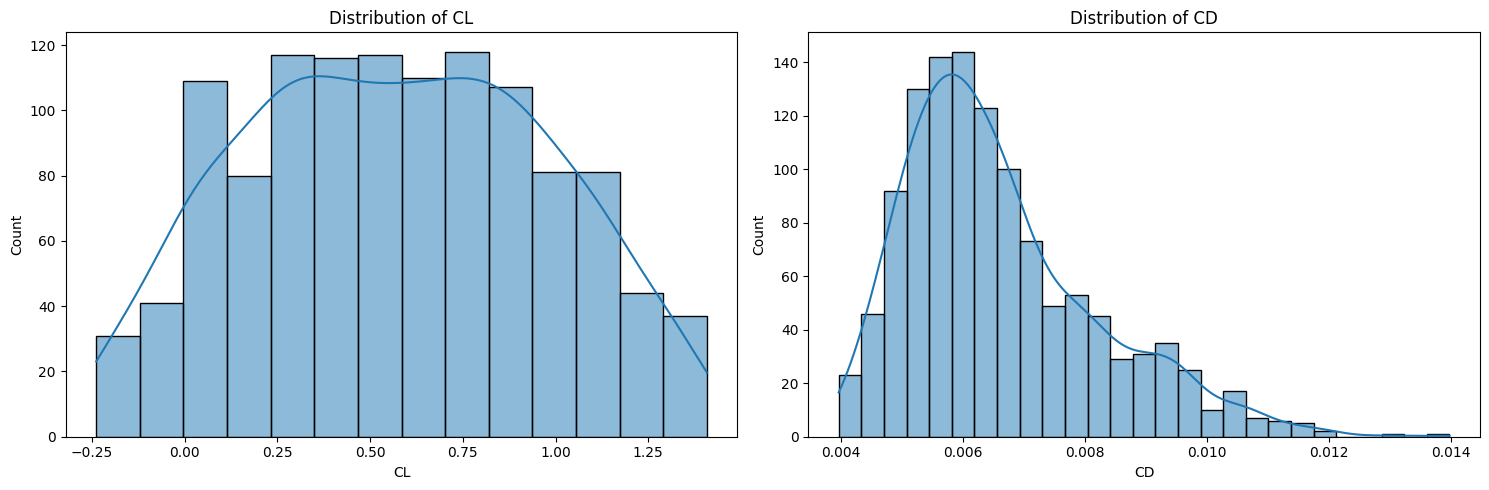

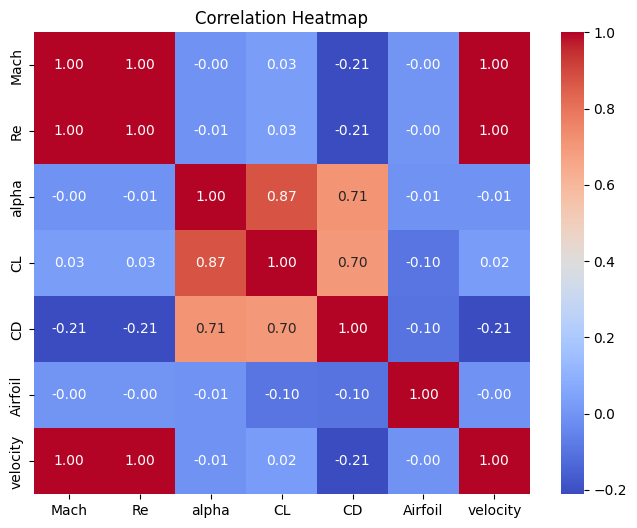

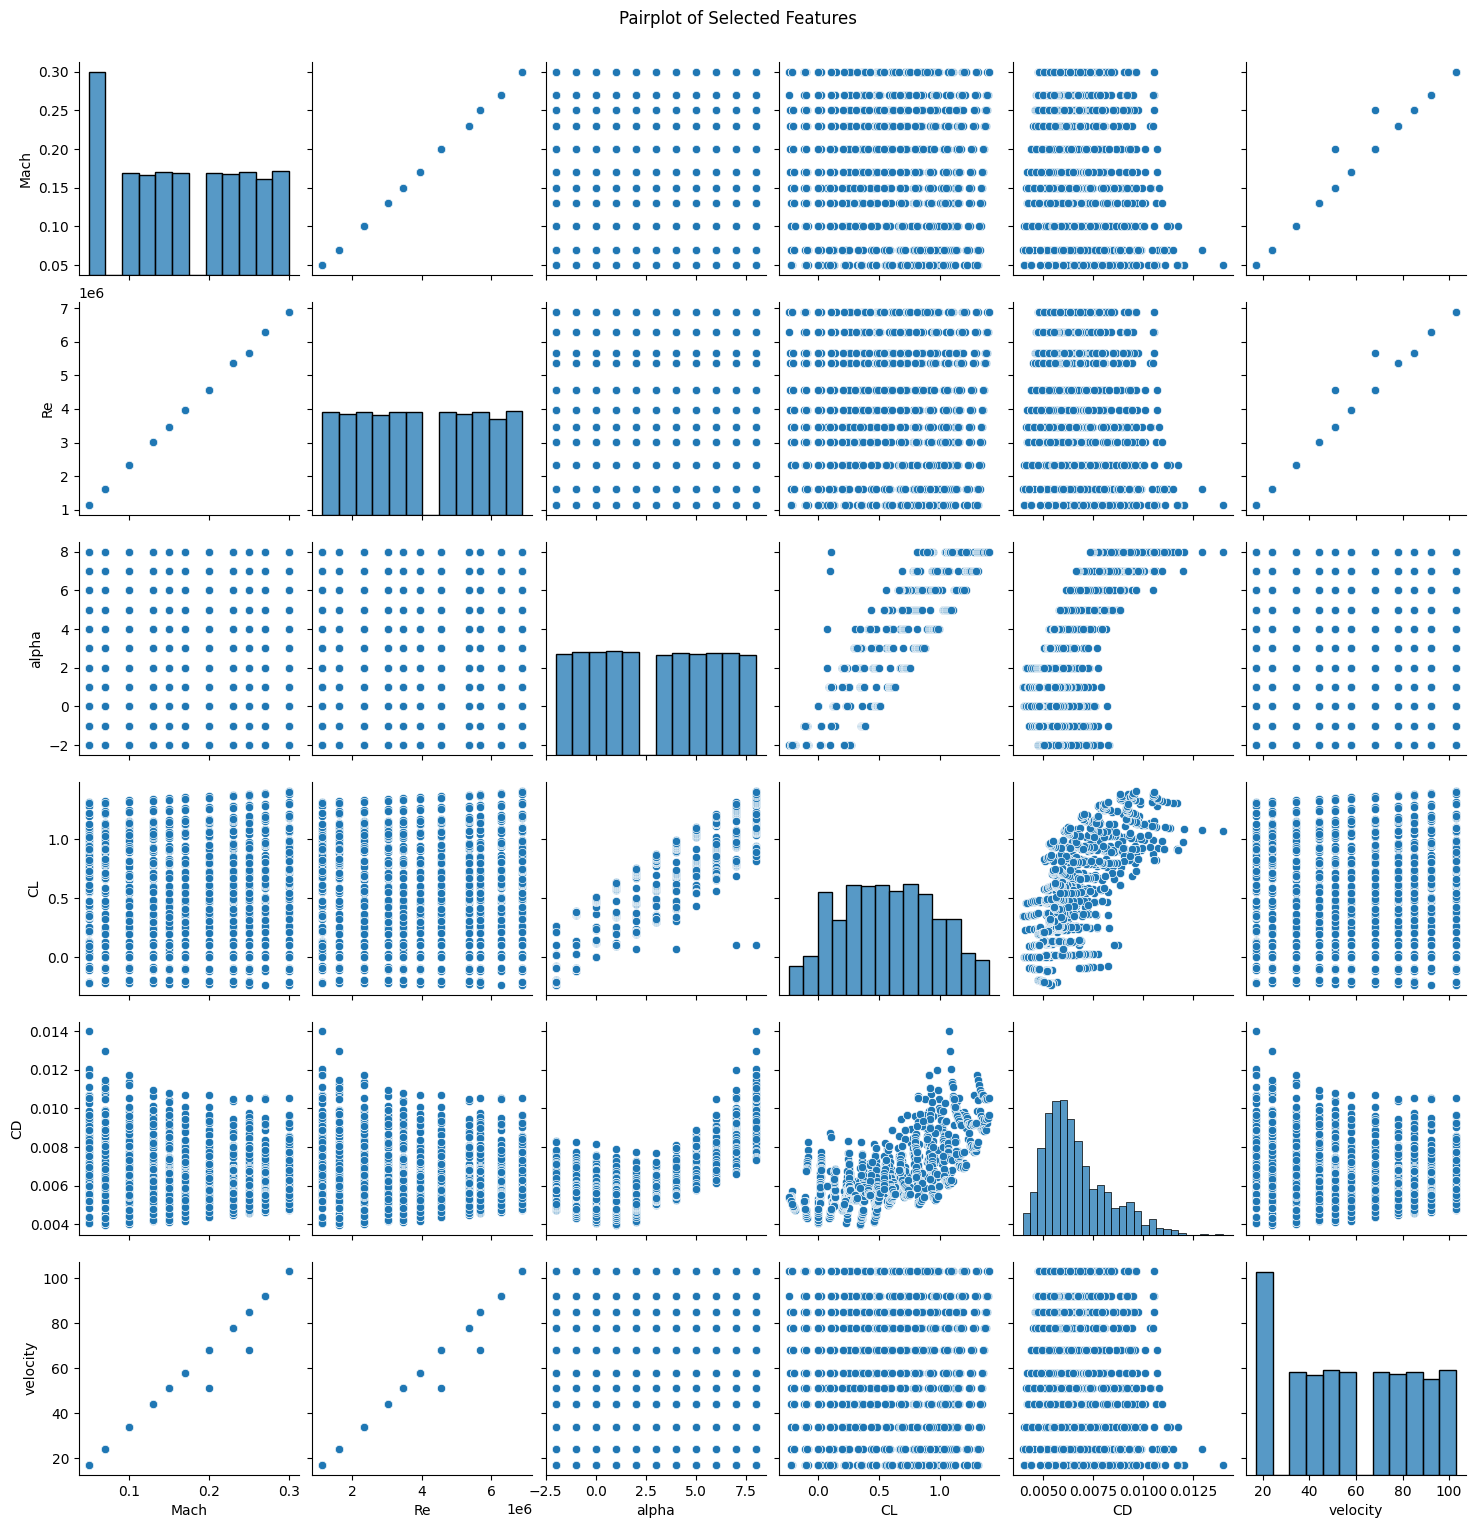

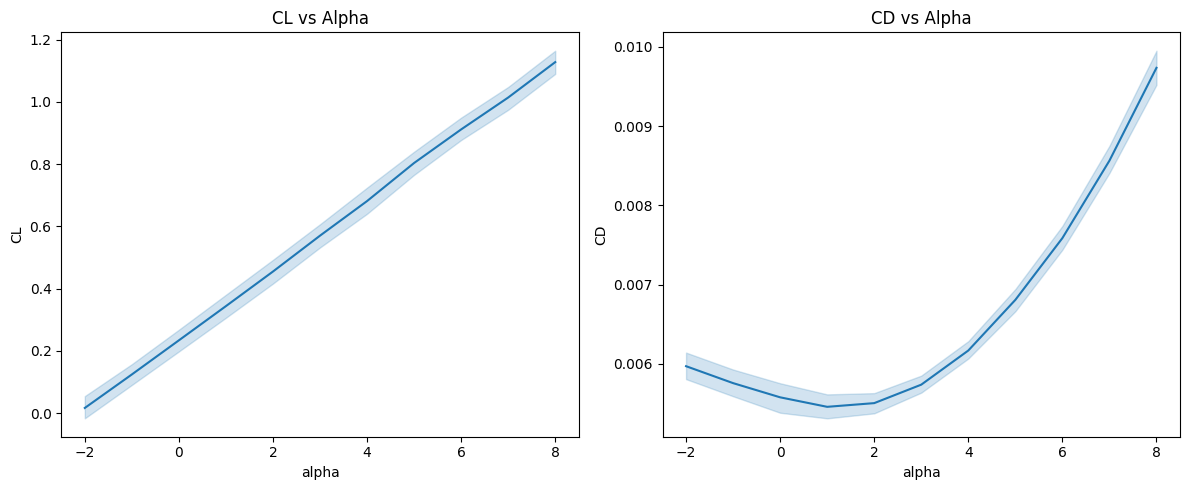

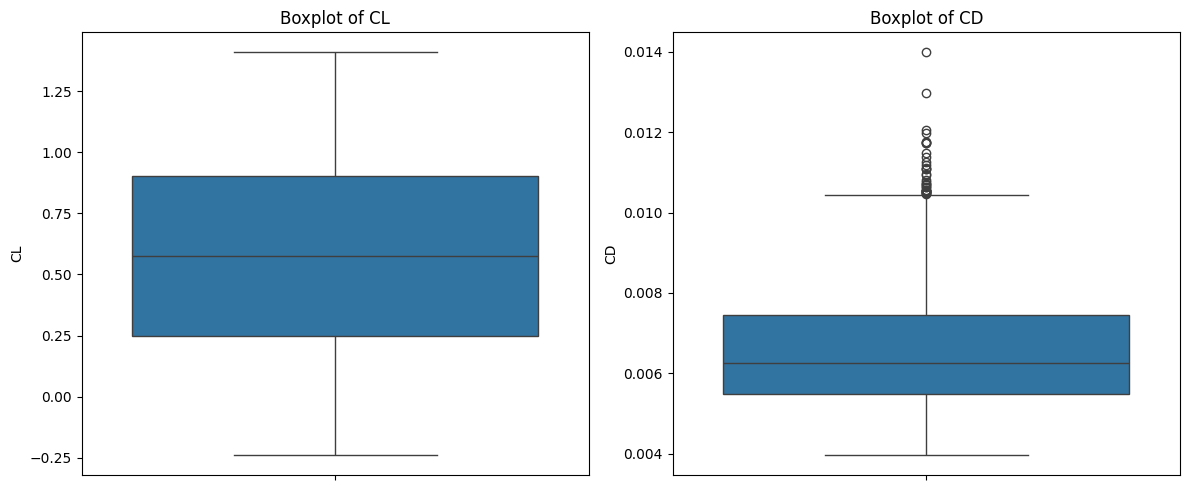

In [ ]:
# STEP 1: Install Required Libraries (only if not already installed)
!pip install seaborn openpyxl

# STEP 2: Import Libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# STEP 3: Load Dataset
from google.colab import files
uploaded = files.upload()

# Replace this with the exact file name you upload
df = pd.read_excel('/content/Final Compiled 2D.xlsx')

# STEP 4: Preview Dataset
print("🔍 Dataset Preview:")
display(df.head())

print("\n📏 Dataset Shape:", df.shape)
print("\n📄 Column Names:", df.columns.tolist())
print("\n📊 Data Types:\n", df.dtypes)

# STEP 5: Summary Statistics
print("\n📈 Summary Statistics:")
display(df.describe())

# STEP 6: Check for Null Values
print("\n🕳️ Null Values:\n", df.isnull().sum())

# STEP 7: Distribution Plots
plt.figure(figsize=(15, 5))
for i, col in enumerate(['CL', 'CD']):
    plt.subplot(1, 2, i+1)
    sns.histplot(df[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# STEP 8: Correlation Heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap')
plt.show()

# STEP 9: Pairplot (only selected columns for clarity)
sns.pairplot(df[['Mach', 'Re', 'alpha', 'CL', 'CD' ,'velocity']])
plt.suptitle('Pairplot of Selected Features', y=1.02)
plt.show()

# STEP 10: CL vs Alpha and CD vs Alpha
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.lineplot(x='alpha', y='CL', data=df)
plt.title('CL vs Alpha')

plt.subplot(1, 2, 2)
sns.lineplot(x='alpha', y='CD', data=df)
plt.title('CD vs Alpha')

plt.tight_layout()
plt.show()

# STEP 11: Boxplot to Detect Outliers
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y='CL', data=df)
plt.title('Boxplot of CL')

plt.subplot(1, 2, 2)
sns.boxplot(y='CD', data=df)
plt.title('Boxplot of CD')

plt.tight_layout()
plt.show()


Removing OUTLIERS


In [ ]:
# STEP 1: Install required libraries
!pip install openpyxl seaborn

# STEP 2: Import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

# STEP 3: Upload the dataset
from google.colab import files
uploaded = files.upload()

# STEP 4: Load Excel file (make sure to upload 'Final compiled 2D.xlsx')
df = pd.read_excel("/content/Final Compiled 2D.xlsx")

# STEP 5: Show basic info
print("Initial dataset shape:", df.shape)
display(df.head())

# STEP 6: IQR Outlier Removal Function
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"\nOutlier Thresholds for {column}:")
    print(f"Lower: {lower_bound:.4f}, Upper: {upper_bound:.4f}")

    # Keep only rows within bounds
    df_filtered = df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]
    print(f"Removed {len(df) - len(df_filtered)} outliers from '{column}'")

    return df_filtered

# STEP 7: Remove outliers using IQR method for CL and CD
df_clean = remove_outliers_iqr(df, 'CL')
df_clean = remove_outliers_iqr(df_clean, 'CD')

print("\n✅ Final shape after outlier removal:", df_clean.shape)

# Optional: Save cleaned data
df_clean.to_excel("Cleaned_2D_Airfoil_Data.xlsx", index=False)
files.download("Cleaned_2D_Airfoil_Data.xlsx")


Saving Final Compiled 2D.xlsx to Final Compiled 2D (1).xlsx
Initial dataset shape: (1189, 7)


,Mach,Re,alpha,CL,CD,Airfoil,velocity
0,0.05,1135000,-2,0.2443,0.00831,0,17
1,0.05,1135000,-1,0.3540,0.00824,0,17
2,0.05,1135000,0,0.4638,0.00817,0,17
3,0.05,1135000,1,0.5702,0.00791,0,17
4,0.05,1135000,2,0.6763,0.00775,0,17



Outlier Thresholds for CL:
Lower: -0.7288, Upper: 1.8789
Removed 0 outliers from 'CL'

Outlier Thresholds for CD:
Lower: 0.0025, Upper: 0.0104
Removed 35 outliers from 'CD'

✅ Final shape after outlier removal: (1154, 7)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Visualizing OUTLIERS

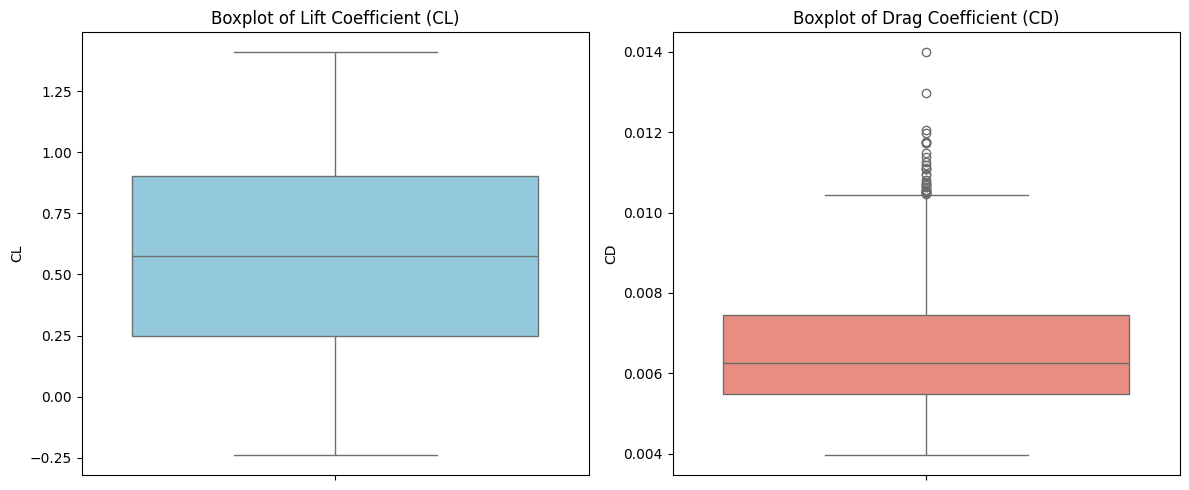

In [ ]:
# 📊 Boxplots to Visualize Outliers
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.boxplot(data=df, y='CL', color='skyblue')
plt.title("Boxplot of Lift Coefficient (CL)")

plt.subplot(1, 2, 2)
sns.boxplot(data=df, y='CD', color='salmon')
plt.title("Boxplot of Drag Coefficient (CD)")

plt.tight_layout()
plt.show()


OPTIONAL: Scatter plots with alpha

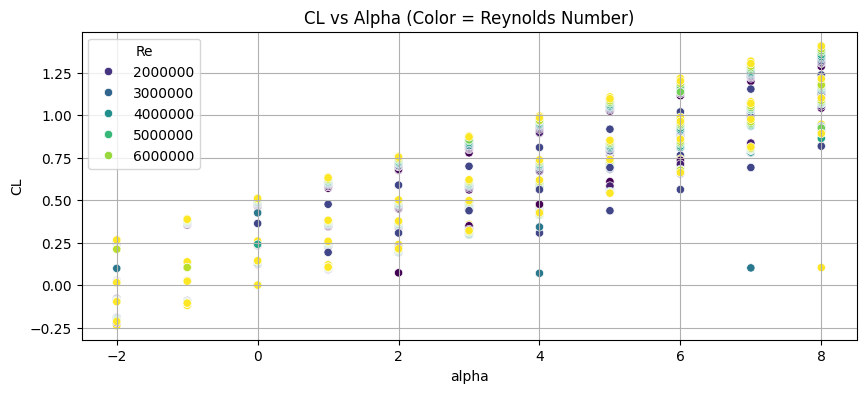

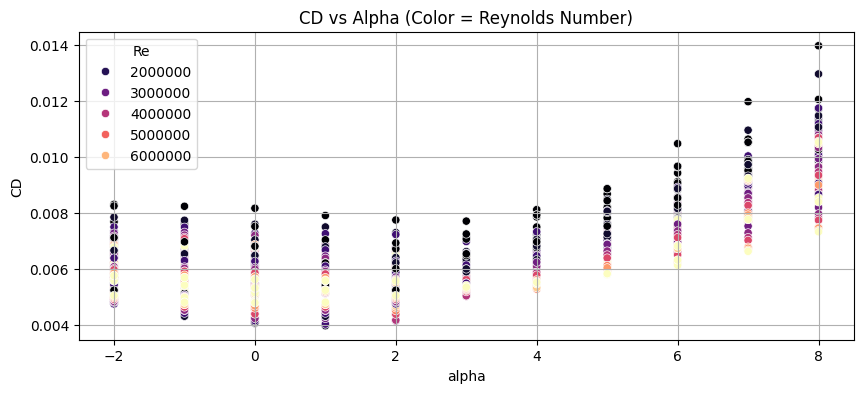

In [ ]:
# 📈 Scatter plot: CL vs Alpha
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x='alpha', y='CL', hue='Re', palette='viridis')
plt.title("CL vs Alpha (Color = Reynolds Number)")
plt.grid(True)
plt.show()

# 📈 Scatter plot: CD vs Alpha
plt.figure(figsize=(10, 4))
sns.scatterplot(data=df, x='alpha', y='CD', hue='Re', palette='magma')
plt.title("CD vs Alpha (Color = Reynolds Number)")
plt.grid(True)
plt.show()


Highlighting outliers

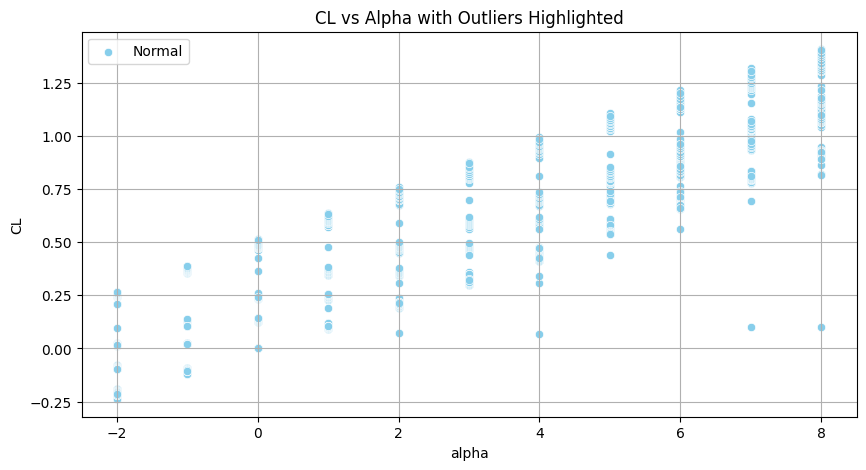

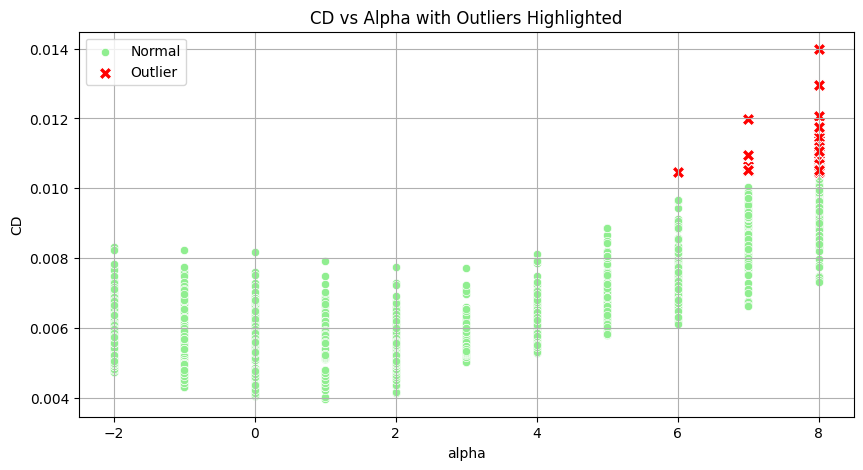

In [ ]:
# Function to get outlier mask using IQR
def get_outlier_mask(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return (df[column] < lower) | (df[column] > upper)

# Get masks for CL and CD outliers
cl_outliers = get_outlier_mask(df, 'CL')
cd_outliers = get_outlier_mask(df, 'CD')

# 📌 Scatter Plot: CL vs Alpha (Highlight outliers)
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df[~cl_outliers], x='alpha', y='CL', label='Normal', color='skyblue')
sns.scatterplot(data=df[cl_outliers], x='alpha', y='CL', label='Outlier', color='red', marker='X', s=80)
plt.title("CL vs Alpha with Outliers Highlighted")
plt.legend()
plt.grid(True)
plt.show()

# 📌 Scatter Plot: CD vs Alpha (Highlight outliers)
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df[~cd_outliers], x='alpha', y='CD', label='Normal', color='lightgreen')
sns.scatterplot(data=df[cd_outliers], x='alpha', y='CD', label='Outlier', color='red', marker='X', s=80)
plt.title("CD vs Alpha with Outliers Highlighted")
plt.legend()
plt.grid(True)
plt.show()


 Remove Outliers (CL + CD) Using IQR

In [ ]:
# Function to remove outliers using IQR
def remove_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return df[(df[column] >= lower_bound) & (df[column] <= upper_bound)]

# Step 1: Remove CL outliers
df_no_outliers = remove_outliers_iqr(df, 'CL')

# Step 2: Remove CD outliers from the filtered result
df_no_outliers = remove_outliers_iqr(df_no_outliers, 'CD')

# Final check
print(f"✅ Cleaned dataset shape: {df_no_outliers.shape}")
display(df_no_outliers.head())

# Save to Excel
df_no_outliers.to_excel("Cleaned_2D_Airfoil_Data.xlsx", index=False)

# Download in Colab
from google.colab import files
files.download("Cleaned_2D_Airfoil_Data.xlsx")



✅ Cleaned dataset shape: (1154, 7)


,Mach,Re,alpha,CL,CD,Airfoil,velocity
0,0.05,1135000,-2,0.2443,0.00831,0,17
1,0.05,1135000,-1,0.3540,0.00824,0,17
2,0.05,1135000,0,0.4638,0.00817,0,17
3,0.05,1135000,1,0.5702,0.00791,0,17
4,0.05,1135000,2,0.6763,0.00775,0,17


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Multiple Linear Regression on Cleaned Airfoil Data

Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (1).xlsx
🔍 Multiple Linear Regression Results:
Mean Squared Error (MSE): 0.0415
R² Score: 0.7079

Model Coefficients:


,Coefficient
Mach,-1.119038e+00
Re,5.606648e-08
alpha,1.136543e-01


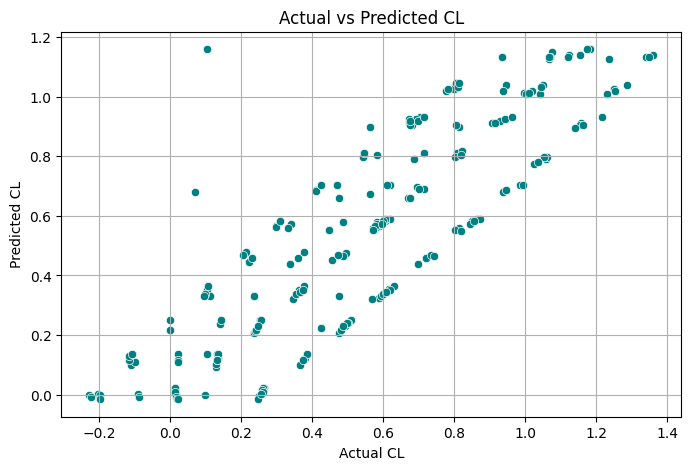

In [ ]:
# 📦 Install & import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 🔄 Upload cleaned dataset if running in Colab
from google.colab import files
uploaded = files.upload()

# 📥 Load dataset
df = pd.read_excel("Cleaned_2D_Airfoil_Data.xlsx")

# 🧠 Define input features and target (Predicting CL)
X = df[['Mach', 'Re', 'alpha']]
y = df['CL']  # You can switch this to 'CD' to predict drag coefficient instead

# 🔀 Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 📈 Train Multiple Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# 📊 Predict on test set
y_pred = model.predict(X_test)

# 📉 Evaluation
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("🔍 Multiple Linear Regression Results:")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"R² Score: {r2:.4f}")

# 📎 Show coefficients
coeff_df = pd.DataFrame(model.coef_, X.columns, columns=['Coefficient'])
print("\nModel Coefficients:")
display(coeff_df)

# 🔍 Optional: Plot predicted vs actual
plt.figure(figsize=(8,5))
sns.scatterplot(x=y_test, y=y_pred, color='teal')
plt.xlabel("Actual CL")
plt.ylabel("Predicted CL")
plt.title("Actual vs Predicted CL")
plt.grid(True)
plt.show()


applying MLR on both Cl and CD

In [ ]:
# 📦 Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 📥 Upload and read your cleaned dataset
from google.colab import files
uploaded = files.upload()
df = pd.read_excel("Cleaned_2D_Airfoil_Data.xlsx")

# 🎯 Features and Targets
X = df[['Mach', 'Re', 'alpha']]
y_cl = df['CL']
y_cd = df['CD']

# 🔀 Split the data (same split for both models)
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# 🔧 Train Models
model_cl = LinearRegression()
model_cl.fit(X_train, y_cl_train)
y_cl_pred = model_cl.predict(X_test)

model_cd = LinearRegression()
model_cd.fit(X_train, y_cd_train)
y_cd_pred = model_cd.predict(X_test)

# 📊 Evaluation
print("🟩 CL Model Performance:")
print(f"R² Score: {r2_score(y_cl_test, y_cl_pred):.4f}")
print(f"MSE: {mean_squared_error(y_cl_test, y_cl_pred):.6f}\n")

print("🟥 CD Model Performance:")
print(f"R² Score: {r2_score(y_cd_test, y_cd_pred):.4f}")
print(f"MSE: {mean_squared_error(y_cd_test, y_cd_pred):.6f}")

# 📎 Coefficients
print("\nModel Coefficients (CL):")
print(pd.DataFrame(model_cl.coef_, index=X.columns, columns=['CL Coefficient']))

print("\nModel Coefficients (CD):")
print(pd.DataFrame(model_cd.coef_, index=X.columns, columns=['CD Coefficient']))


Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (2).xlsx
🟩 CL Model Performance:
R² Score: 0.7079
MSE: 0.041457

🟥 CD Model Performance:
R² Score: 0.4376
MSE: 0.000001

Model Coefficients (CL):
       CL Coefficient
Mach    -1.119038e+00
Re       5.606648e-08
alpha    1.136543e-01

Model Coefficients (CD):
       CD Coefficient
Mach     1.964419e-02
Re      -9.960180e-10
alpha    3.291398e-04


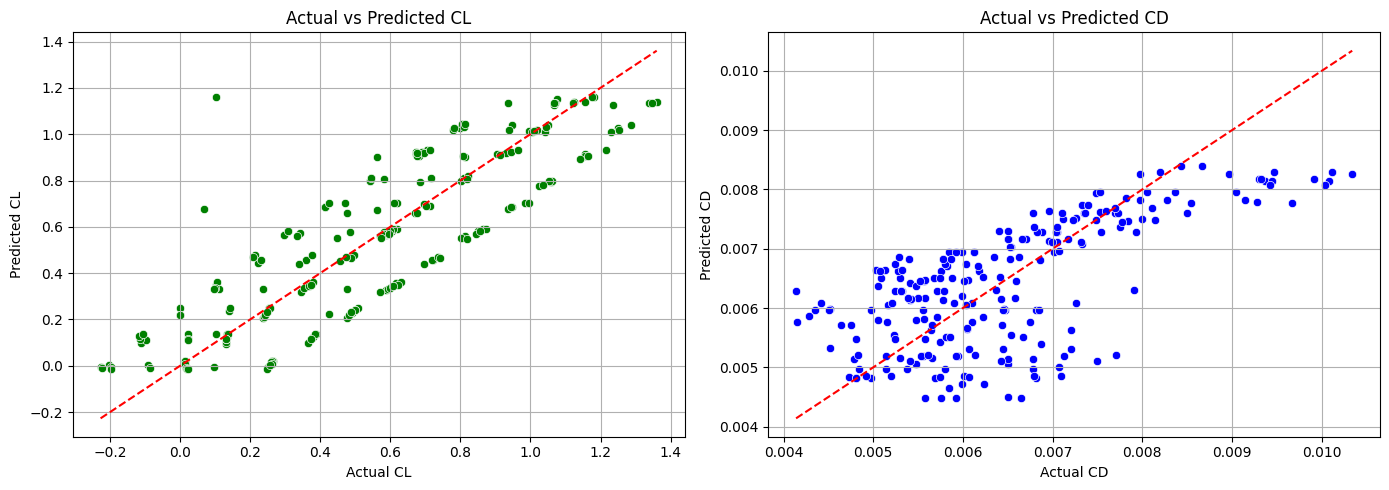

In [ ]:
# Actual vs Predicted Plots for CL and CD
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# CL Plot
sns.scatterplot(x=y_cl_test, y=y_cl_pred, ax=axs[0], color='green')
axs[0].plot([y_cl_test.min(), y_cl_test.max()], [y_cl_test.min(), y_cl_test.max()], '--r')
axs[0].set_title("Actual vs Predicted CL")
axs[0].set_xlabel("Actual CL")
axs[0].set_ylabel("Predicted CL")
axs[0].grid(True)

# CD Plot
sns.scatterplot(x=y_cd_test, y=y_cd_pred, ax=axs[1], color='blue')
axs[1].plot([y_cd_test.min(), y_cd_test.max()], [y_cd_test.min(), y_cd_test.max()], '--r')
axs[1].set_title("Actual vs Predicted CD")
axs[1].set_xlabel("Actual CD")
axs[1].set_ylabel("Predicted CD")
axs[1].grid(True)

plt.tight_layout()
plt.show()


In [ ]:
pred_df = pd.DataFrame({
    'Mach': X_test['Mach'],
    'Re': X_test['Re'],
    'alpha': X_test['alpha'],
    'Actual_CL': y_cl_test,
    'Predicted_CL': y_cl_pred,
    'Actual_CD': y_cd_test,
    'Predicted_CD': y_cd_pred
})
pred_df.to_excel("Airfoil_Regression_Results.xlsx", index=False)


Applying Multiple regressor on Cl and Cd separately

In [ ]:
# =========================
# 📦 IMPORT LIBRARIES
# =========================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

# =========================
# 📥 LOAD DATA
# =========================
# Upload the file manually if using Colab:
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Cleaned_2D_Airfoil_Data.xlsx")

# =========================
# 🧹 DATA CLEANING
# =========================
# Drop missing rows (if any)
df.dropna(inplace=True)

# =========================
# 🎯 FEATURES AND TARGETS
# =========================
X = df[['Mach', 'Re', 'Alpha']]  # Features

y_CL = df['CL']  # Target 1
y_CD = df['CD']  # Target 2

# =========================
# ✈️ CL MODEL
# =========================
X_train_cl, X_test_cl, y_train_cl, y_test_cl = train_test_split(X, y_CL, test_size=0.2, random_state=42)

model_cl = LinearRegression()
model_cl.fit(X_train_cl, y_train_cl)

y_pred_cl = model_cl.predict(X_test_cl)

r2_cl = r2_score(y_test_cl, y_pred_cl)
mse_cl = mean_squared_error(y_test_cl, y_pred_cl)

print("\n✈️ CL Model:")
print(f"R² Score: {r2_cl:.4f}")
print(f"MSE: {mse_cl:.6f}")

# =========================
# 🌪 CD MODEL
# =========================
X_train_cd, X_test_cd, y_train_cd, y_test_cd = train_test_split(X, y_CD, test_size=0.2, random_state=42)

model_cd = LinearRegression()
model_cd.fit(X_train_cd, y_train_cd)

y_pred_cd = model_cd.predict(X_test_cd)

r2_cd = r2_score(y_test_cd, y_pred_cd)
mse_cd = mean_squared_error(y_test_cd, y_pred_cd)

print("\n🌪 CD Model:")
print(f"R² Score: {r2_cd:.4f}")
print(f"MSE: {mse_cd:.6f}")

# =========================
# 📊 VISUALIZATION
# =========================

plt.figure(figsize=(14, 6))

# CL Plot
plt.subplot(1, 2, 1)
plt.scatter(y_test_cl, y_pred_cl, c='blue', label='CL Predictions')
plt.plot([y_test_cl.min(), y_test_cl.max()], [y_test_cl.min(), y_test_cl.max()], 'k--')
plt.xlabel("Actual CL")
plt.ylabel("Predicted CL")
plt.title("CL: Actual vs Predicted")
plt.legend()

# CD Plot
plt.subplot(1, 2, 2)
plt.scatter(y_test_cd, y_pred_cd, c='red', label='CD Predictions')
plt.plot([y_test_cd.min(), y_test_cd.max()], [y_test_cd.min(), y_test_cd.max()], 'k--')
plt.xlabel("Actual CD")
plt.ylabel("Predicted CD")
plt.title("CD: Actual vs Predicted")
plt.legend()

plt.tight_layout()
plt.show()


Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (4).xlsx


KeyError: "['Alpha'] not in index"

Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (5).xlsx
   mach       re  alpha      cl       cd  airfoil  velocity
0  0.05  1135000     -2  0.2443  0.00831        0        17
1  0.05  1135000     -1  0.3540  0.00824        0        17
2  0.05  1135000      0  0.4638  0.00817        0        17
3  0.05  1135000      1  0.5702  0.00791        0        17
4  0.05  1135000      2  0.6763  0.00775        0        17


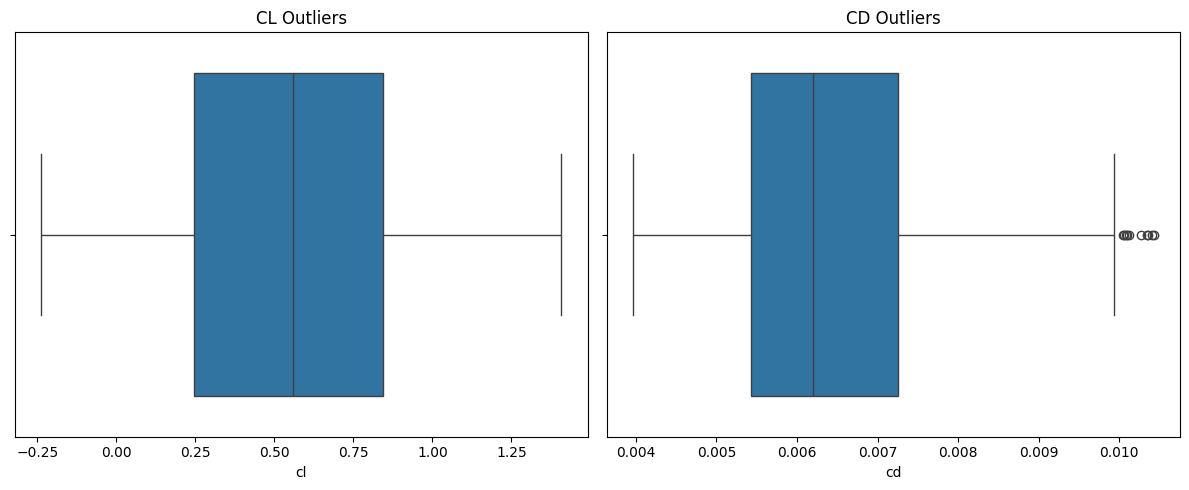

🔹 CL Model:
R² Score: 0.7078578848919411
MSE: 0.04145669263816438

🔹 CD Model:
R² Score: 0.4375993052028323
MSE: 9.299758312592733e-07


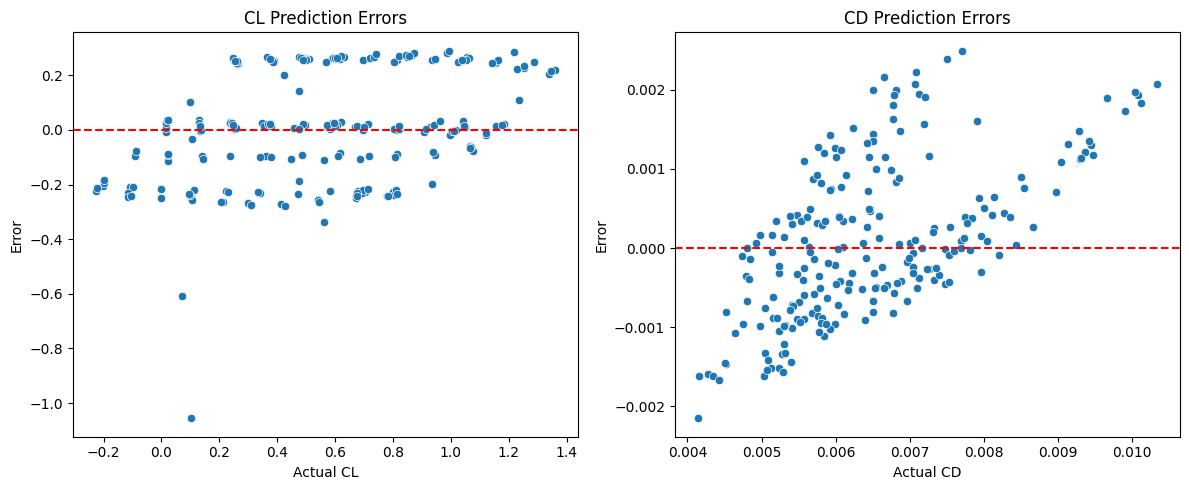

In [ ]:
# ===============================
# 📦 Import Libraries
# ===============================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# ===============================
# 📁 Load and Preprocess Dataset
# ===============================
# Upload your file in Colab
from google.colab import files
uploaded = files.upload()

# Load Excel file
df = pd.read_excel("/content/Cleaned_2D_Airfoil_Data.xlsx")

# Standardize column names
df.columns = df.columns.str.strip().str.lower()

# Show first few rows
print(df.head())

# ===============================
# 📊 EDA: Visualize Outliers
# ===============================
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x=df['cl'])
plt.title("CL Outliers")

plt.subplot(1, 2, 2)
sns.boxplot(x=df['cd'])
plt.title("CD Outliers")
plt.tight_layout()
plt.show()

# ===============================
# 🧹 Outlier Removal (Z-score method)
# ===============================
from scipy import stats
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ===============================
# 🎯 Define Features & Targets
# ===============================
X = df[['mach', 're', 'alpha']]

# Targets
y_cl = df['cl']
y_cd = df['cd']

# ===============================
# 📈 Split Dataset
# ===============================
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# ===============================
# 🤖 Model for CL
# ===============================
model_cl = LinearRegression()
model_cl.fit(X_train, y_cl_train)
y_cl_pred = model_cl.predict(X_test)

# ===============================
# 🤖 Model for CD
# ===============================
model_cd = LinearRegression()
model_cd.fit(X_train, y_cd_train)
y_cd_pred = model_cd.predict(X_test)

# ===============================
# 📊 Model Evaluation
# ===============================
print("🔹 CL Model:")
print("R² Score:", r2_score(y_cl_test, y_cl_pred))
print("MSE:", mean_squared_error(y_cl_test, y_cl_pred))

print("\n🔹 CD Model:")
print("R² Score:", r2_score(y_cd_test, y_cd_pred))
print("MSE:", mean_squared_error(y_cd_test, y_cd_pred))

# ===============================
# 📉 Error Visualization
# ===============================
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_cl_test, y=y_cl_test - y_cl_pred)
plt.axhline(0, color='red', linestyle='--')
plt.title("CL Prediction Errors")
plt.xlabel("Actual CL")
plt.ylabel("Error")

plt.subplot(1, 2, 2)
sns.scatterplot(x=y_cd_test, y=y_cd_test - y_cd_pred)
plt.axhline(0, color='red', linestyle='--')
plt.title("CD Prediction Errors")
plt.xlabel("Actual CD")
plt.ylabel("Error")

plt.tight_layout()
plt.show()


Applying XG boost

Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (6).xlsx
🔹 CL Model (XGBoost)
R² Score: 0.6523983040461464
MSE: 0.049326734915756267

🔹 CD Model (XGBoost)
R² Score: 0.7102894878671543
MSE: 4.790601733564035e-07


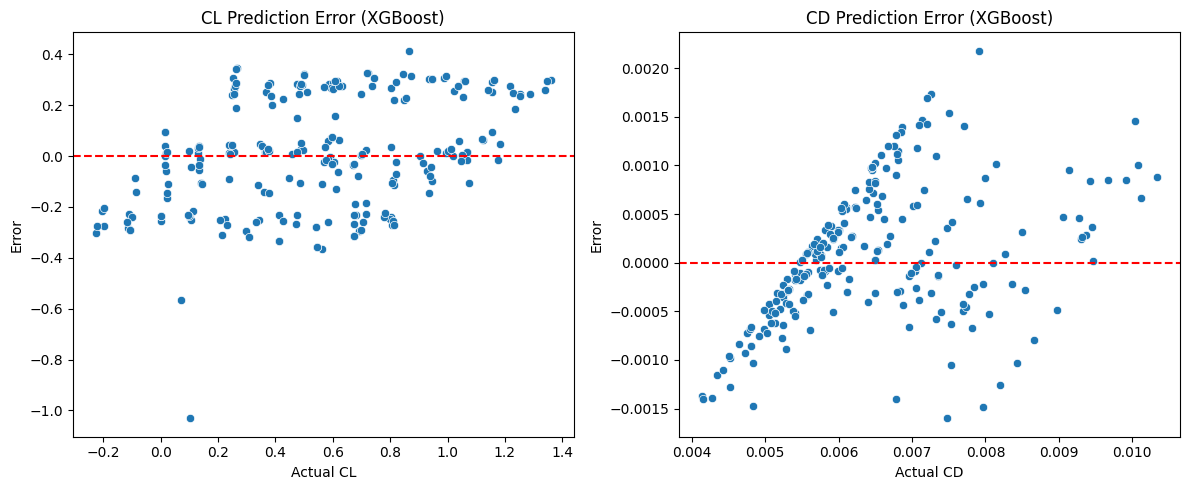

In [ ]:
# ===============================
# 📦 Install & Import Libraries
# ===============================
!pip install xgboost openpyxl --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

from xgboost import XGBRegressor

# ===============================
# 📁 Load Data
# ===============================
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Cleaned_2D_Airfoil_Data.xlsx")

# Clean column names
df.columns = df.columns.str.strip().str.lower()

# ===============================
# 🧹 Remove Outliers
# ===============================
from scipy import stats
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ===============================
# 🎯 Features & Targets
# ===============================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# ===============================
# 🌲 XGBoost for CL
# ===============================
model_cl_xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model_cl_xgb.fit(X_train, y_cl_train)
y_cl_pred = model_cl_xgb.predict(X_test)

# ===============================
# 🌲 XGBoost for CD
# ===============================
model_cd_xgb = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
model_cd_xgb.fit(X_train, y_cd_train)
y_cd_pred = model_cd_xgb.predict(X_test)

# ===============================
# 📊 Model Performance
# ===============================
print("🔹 CL Model (XGBoost)")
print("R² Score:", r2_score(y_cl_test, y_cl_pred))
print("MSE:", mean_squared_error(y_cl_test, y_cl_pred))

print("\n🔹 CD Model (XGBoost)")
print("R² Score:", r2_score(y_cd_test, y_cd_pred))
print("MSE:", mean_squared_error(y_cd_test, y_cd_pred))

# ===============================
# 📉 Error Visualization
# ===============================
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_cl_test, y=y_cl_test - y_cl_pred)
plt.axhline(0, color='red', linestyle='--')
plt.title("CL Prediction Error (XGBoost)")
plt.xlabel("Actual CL")
plt.ylabel("Error")

plt.subplot(1, 2, 2)
sns.scatterplot(x=y_cd_test, y=y_cd_test - y_cd_pred)
plt.axhline(0, color='red', linestyle='--')
plt.title("CD Prediction Error (XGBoost)")
plt.xlabel("Actual CD")
plt.ylabel("Error")

plt.tight_layout()
plt.show()


Comparison b/w Regressor and Xg boost

Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (7).xlsx
        Model  R2 Score           MSE
0   Linear CL  0.707858  4.145669e-02
1  XGBoost CL  0.652398  4.932673e-02
2   Linear CD  0.437599  9.299758e-07
3  XGBoost CD  0.710289  4.790602e-07


<ipython-input-16-2478506974>:86: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Set2")
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


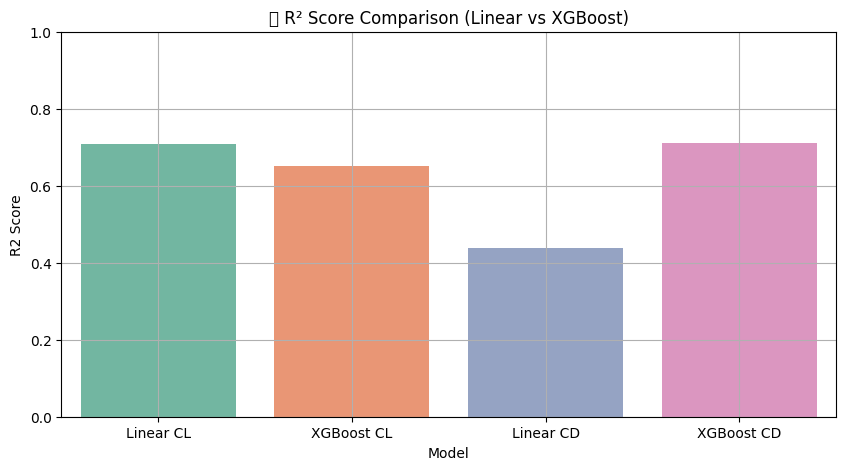

<ipython-input-16-2478506974>:93: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="MSE", palette="Set3")
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


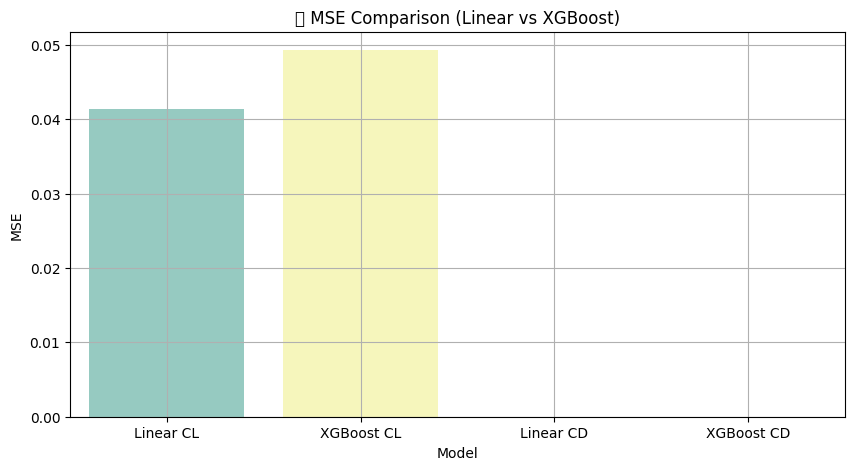

In [ ]:
# 📦 Install necessary libraries (if not already installed)
!pip install xgboost openpyxl --quiet

# =======================
# 📚 Import Libraries
# =======================
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats

# =======================
# 📁 Upload Excel Dataset
# =======================
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Cleaned_2D_Airfoil_Data.xlsx")
df.columns = df.columns.str.strip().str.lower()

# =======================
# 🚫 Remove Outliers
# =======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# =======================
# 🎯 Features and Targets
# =======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# =======================
# 🤖 Train Both Models
# =======================

# CL
lr_cl = LinearRegression().fit(X_train, y_cl_train)
xgb_cl = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42).fit(X_train, y_cl_train)

# CD
lr_cd = LinearRegression().fit(X_train, y_cd_train)
xgb_cd = XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42).fit(X_train, y_cd_train)

# =======================
# 📊 Evaluate All Models
# =======================
def evaluate(model, X_test, y_test, label):
    pred = model.predict(X_test)
    return {
        "Model": label,
        "R2 Score": r2_score(y_test, pred),
        "MSE": mean_squared_error(y_test, pred)
    }

results = []

# CL Evaluation
results.append(evaluate(lr_cl, X_test, y_cl_test, "Linear CL"))
results.append(evaluate(xgb_cl, X_test, y_cl_test, "XGBoost CL"))

# CD Evaluation
results.append(evaluate(lr_cd, X_test, y_cd_test, "Linear CD"))
results.append(evaluate(xgb_cd, X_test, y_cd_test, "XGBoost CD"))

# =======================
# 📋 Display Results
# =======================
results_df = pd.DataFrame(results)
print(results_df)

# =======================
# 📉 Visualization
# =======================
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Set2")
plt.title("📈 R² Score Comparison (Linear vs XGBoost)")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MSE", palette="Set3")
plt.title("📉 MSE Comparison (Linear vs XGBoost)")
plt.grid(True)
plt.show()


Apply SVR

Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (8).xlsx
      Model  R2 Score           MSE
0  SVR - CL  0.696032  4.313482e-02
1  SVR - CD  0.646181  5.850682e-07


<ipython-input-19-2007045829>:82: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Blues")


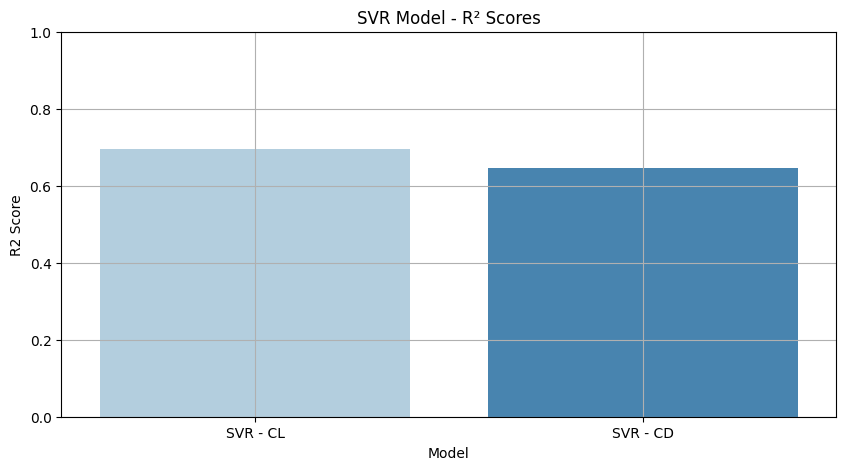

<ipython-input-19-2007045829>:89: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="MSE", palette="Reds")


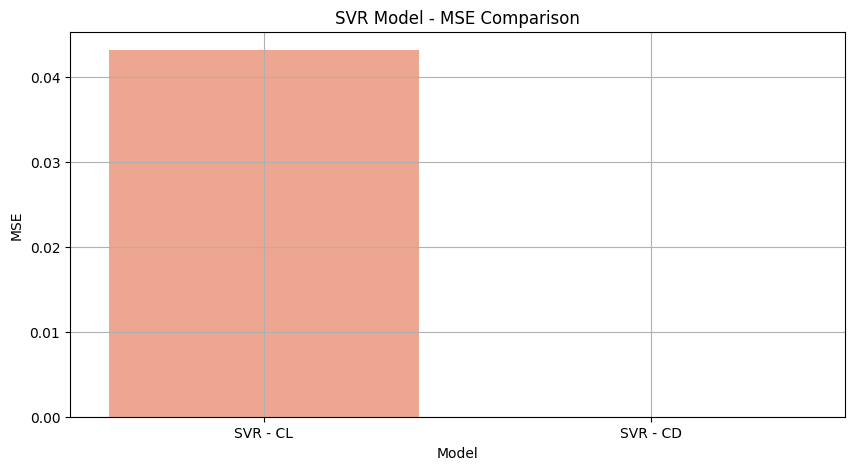

In [ ]:
# 📦 Install dependencies if not installed
!pip install openpyxl scikit-learn --quiet

# =======================
# 📚 Import Libraries
# =======================
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats

# =======================
# 📁 Load the dataset
# =======================
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Cleaned_2D_Airfoil_Data.xlsx")
df.columns = df.columns.str.strip().str.lower()

# =======================
# 🚫 Remove Outliers
# =======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# =======================
# 🎯 Features & Targets
# =======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# Split data
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# =======================
# 🔄 Scale the features
# =======================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =======================
# 🤖 Train SVR Models
# =======================
svr_cl = SVR(kernel='rbf', C=100, epsilon=0.01)
svr_cl.fit(X_train_scaled, y_cl_train)

svr_cd = SVR(kernel='rbf', C=100, epsilon=0.001)
svr_cd.fit(X_train_scaled, y_cd_train)

# =======================
# 📊 Evaluate Models
# =======================
def evaluate(model, X_test, y_test, label):
    preds = model.predict(X_test)
    return {
        "Model": label,
        "R2 Score": r2_score(y_test, preds),
        "MSE": mean_squared_error(y_test, preds)
    }

results = []
results.append(evaluate(svr_cl, X_test_scaled, y_cl_test, "SVR - CL"))
results.append(evaluate(svr_cd, X_test_scaled, y_cd_test, "SVR - CD"))

# Show results
results_df = pd.DataFrame(results)
print(results_df)

# =======================
# 📉 Visualize Errors
# =======================
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Blues")
plt.title("SVR Model - R² Scores")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MSE", palette="Reds")
plt.title("SVR Model - MSE Comparison")
plt.grid(True)
plt.show()


Tuning

Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (9).xlsx
✅ Best CL SVR Params: {'C': 1, 'epsilon': 0.001, 'gamma': 'auto'}
✅ Best CD SVR Params: {'C': 1, 'epsilon': 0.001, 'gamma': 'scale'}
            Model  R2 Score           MSE
0  Tuned SVR - CL  0.704703  4.190436e-02
1  Tuned SVR - CD  0.646181  5.850682e-07


<ipython-input-20-191157163>:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Blues")


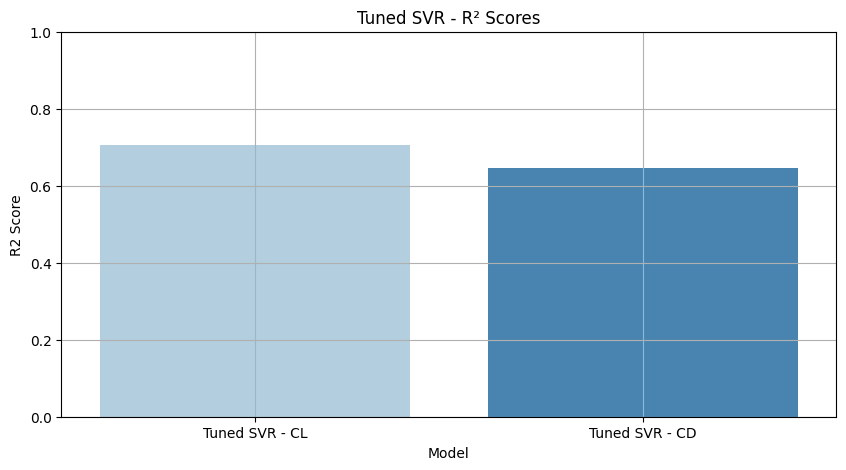

<ipython-input-20-191157163>:99: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="MSE", palette="Reds")


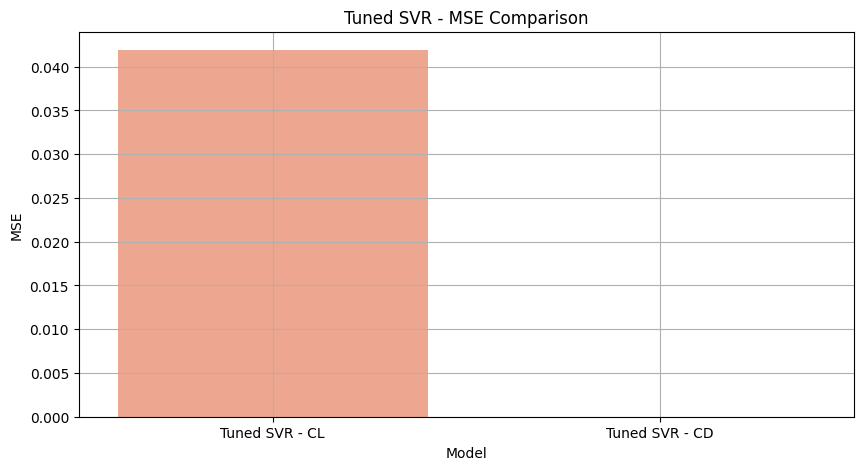

In [ ]:
# 📦 Install dependencies if not installed
!pip install openpyxl scikit-learn --quiet

# =======================
# 📚 Import Libraries
# =======================
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats

# =======================
# 📁 Load the dataset
# =======================
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Cleaned_2D_Airfoil_Data.xlsx")
df.columns = df.columns.str.strip().str.lower()

# =======================
# 🚫 Remove Outliers
# =======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# =======================
# 🎯 Features & Targets
# =======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# =======================
# 🔄 Scale the features
# =======================
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# =======================
# 🔧 Hyperparameter Tuning
# =======================
param_grid = {
    'C': [1, 10, 100, 500],
    'epsilon': [0.0001, 0.001, 0.01],
    'gamma': ['scale', 'auto']
}

grid_cl = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_cl.fit(X_train_scaled, y_cl_train)

grid_cd = GridSearchCV(SVR(kernel='rbf'), param_grid, cv=5, scoring='r2', n_jobs=-1)
grid_cd.fit(X_train_scaled, y_cd_train)

best_svr_cl = grid_cl.best_estimator_
best_svr_cd = grid_cd.best_estimator_

print("✅ Best CL SVR Params:", grid_cl.best_params_)
print("✅ Best CD SVR Params:", grid_cd.best_params_)

# =======================
# 📊 Evaluate Models
# =======================
def evaluate(model, X_test, y_test, label):
    preds = model.predict(X_test)
    return {
        "Model": label,
        "R2 Score": r2_score(y_test, preds),
        "MSE": mean_squared_error(y_test, preds)
    }

results = []
results.append(evaluate(best_svr_cl, X_test_scaled, y_cl_test, "Tuned SVR - CL"))
results.append(evaluate(best_svr_cd, X_test_scaled, y_cd_test, "Tuned SVR - CD"))

results_df = pd.DataFrame(results)
print(results_df)

# =======================
# 📈 Visualize Errors
# =======================
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Blues")
plt.title("Tuned SVR - R² Scores")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MSE", palette="Reds")
plt.title("Tuned SVR - MSE Comparison")
plt.grid(True)
plt.show()


Applying Random Forest


Saving Cleaned_2D_Airfoil_Data.xlsx to Cleaned_2D_Airfoil_Data (1).xlsx
                Model  R2 Score           MSE
0  Random Forest - CL  0.690433  4.810629e-02
1  Random Forest - CD  0.766866  5.779731e-07


/tmp/ipython-input-1-2044768471.py:91: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Greens")


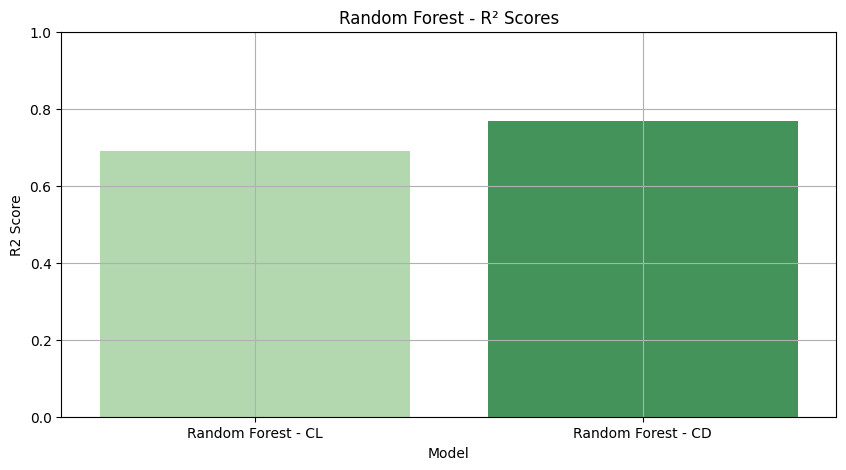

/tmp/ipython-input-1-2044768471.py:98: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results_df, x="Model", y="MSE", palette="Oranges")


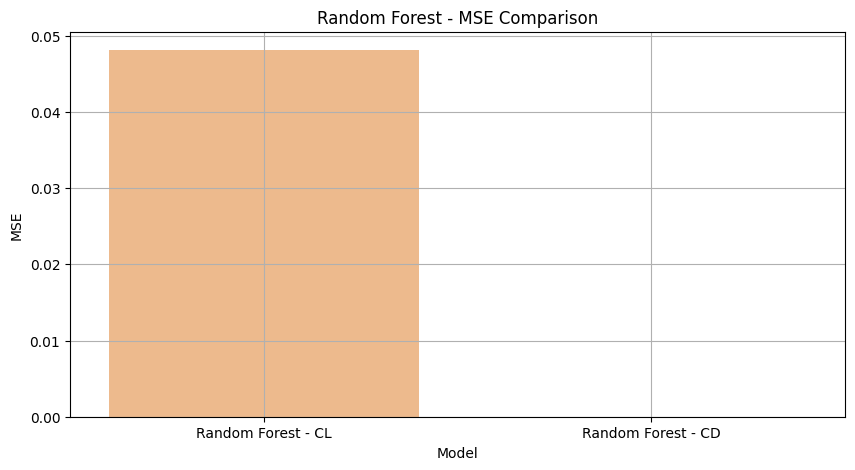

In [ ]:
# 📦 Install dependencies (if not already)
!pip install openpyxl scikit-learn --quiet

# ==============================
# 📚 Import Libraries
# ==============================
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from scipy import stats

# ==============================
# 📁 Load the dataset
# ==============================
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Final Compiled 2D.xlsx")
df.columns = df.columns.str.strip().str.lower()

# ==============================
# 🚫 Remove Outliers
# ==============================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ==============================
# 🔧 Feature Engineering
# ==============================
df['alpha_rad'] = np.radians(df['alpha'])
df['alpha^2'] = df['alpha'] ** 2
df['mach^2'] = df['mach'] ** 2
df['re_alpha'] = df['re'] * df['alpha']
df['mach_alpha'] = df['mach'] * df['alpha']
df['sin_alpha'] = np.sin(df['alpha_rad'])
df['cos_alpha'] = np.cos(df['alpha_rad'])

# ==============================
# 🎯 Feature Matrix & Targets
# ==============================
features = ['mach', 're', 'alpha', 'alpha^2', 'mach^2', 're_alpha', 'mach_alpha', 'sin_alpha', 'cos_alpha']
X = df[features]
y_cl = df['cl']
y_cd = df['cd']

# ==============================
# 🔀 Train-Test Split
# ==============================
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# ==============================
# 🤖 Random Forest Models
# ==============================
rf_cl = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
rf_cl.fit(X_train, y_cl_train)

rf_cd = RandomForestRegressor(n_estimators=200, max_depth=15, random_state=42)
rf_cd.fit(X_train, y_cd_train)

# ==============================
# 📊 Evaluation Function
# ==============================
def evaluate(model, X_test, y_test, label):
    preds = model.predict(X_test)
    return {
        "Model": label,
        "R2 Score": r2_score(y_test, preds),
        "MSE": mean_squared_error(y_test, preds)
    }

results = []
results.append(evaluate(rf_cl, X_test, y_cl_test, "Random Forest - CL"))
results.append(evaluate(rf_cd, X_test, y_cd_test, "Random Forest - CD"))

# ==============================
# 📋 Show Results
# ==============================
results_df = pd.DataFrame(results)
print(results_df)

# ==============================
# 📉 Visualize Scores
# ==============================
plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="R2 Score", palette="Greens")
plt.title("Random Forest - R² Scores")
plt.ylim(0, 1)
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
sns.barplot(data=results_df, x="Model", y="MSE", palette="Oranges")
plt.title("Random Forest - MSE Comparison")
plt.grid(True)
plt.show()


tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

# ==============================
# 🔍 Define Parameter Grid
# ==============================
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['auto', 'sqrt']
}

# ==============================
# 🎯 Grid Search for CL
# ==============================
grid_cl = GridSearchCV(RandomForestRegressor(random_state=42), param_grid,
                       cv=5, scoring='r2', n_jobs=-1, verbose=1)
grid_cl.fit(X_train, y_cl_train)

# Best model for CL
best_rf_cl = grid_cl.best_estimator_
print("Best RF-CL params:", grid_cl.best_params_)

# ==============================
# 🎯 Grid Search for CD
# ==============================
grid_cd = GridSearchCV(RandomForestRegressor(random_state=42), param_grid,
                       cv=5, scoring='r2', n_jobs=-1, verbose=1)
grid_cd.fit(X_train, y_cd_train)

# Best model for CD
best_rf_cd = grid_cd.best_estimator_
print("Best RF-CD params:", grid_cd.best_params_)

# ==============================
# 📊 Evaluate Best Models
# ==============================
results = []
results.append(evaluate(best_rf_cl, X_test, y_cl_test, "Tuned RF - CL"))
results.append(evaluate(best_rf_cd, X_test, y_cd_test, "Tuned RF - CD"))

results_df = pd.DataFrame(results)
print(results_df)


Fitting 5 folds for each of 72 candidates, totalling 360 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
180 fits failed out of a total of 360.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
96 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.11/dist-packages/sklearn/utils

Best RF-CL params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 300}
Fitting 5 folds for each of 72 candidates, totalling 360 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
180 fits failed out of a total of 360.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
90 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_parameter_constraints(
  File "/usr/local/lib/python3.11/dist-packages/sklearn/utils

Best RF-CD params: {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
           Model  R2 Score           MSE
0  Tuned RF - CL  0.692828  4.773413e-02
1  Tuned RF - CD  0.772581  5.638057e-07


Randomized search

In [ ]:
# 📦 Install required packages if not already
!pip install openpyxl scikit-learn --quiet

# ======================
# 📚 Import Libraries
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats

# ======================
# 📁 Load Dataset
# ======================
from google.colab import files
uploaded = files.upload()

df = pd.read_excel("/content/Final Compiled 2D.xlsx")
df.columns = df.columns.str.strip().str.lower()

# ======================
# 🚫 Remove Outliers
# ======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ======================
# 🎯 Features & Targets
# ======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# ======================
# 🔀 Train-Test Split
# ======================
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# ======================
# ⚙️ Random Forest + Randomized Search Pipeline
# ======================
param_dist = {
    'rf__n_estimators': [100, 200, 300, 500],
    'rf__max_depth': [10, 20, 30, None],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 4],
    'rf__max_features': ['auto', 'sqrt', 'log2']
}

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rf', RandomForestRegressor(random_state=42))
])

# CL Model
random_search_cl = RandomizedSearchCV(
    pipeline, param_distributions=param_dist, n_iter=30,
    cv=5, scoring='r2', verbose=1, n_jobs=-1, random_state=42
)
random_search_cl.fit(X_train, y_cl_train)
best_cl_model = random_search_cl.best_estimator_
cl_preds = best_cl_model.predict(X_test)

print("\n🔍 Tuned Random Forest - CL")
print("Best Parameters:", random_search_cl.best_params_)
print("R2 Score:", r2_score(y_cl_test, cl_preds))
print("MSE:", mean_squared_error(y_cl_test, cl_preds))

# CD Model
random_search_cd = RandomizedSearchCV(
    pipeline, param_distributions=param_dist, n_iter=30,
    cv=5, scoring='r2', verbose=1, n_jobs=-1, random_state=42
)
random_search_cd.fit(X_train, y_cd_train)
best_cd_model = random_search_cd.best_estimator_
cd_preds = best_cd_model.predict(X_test)

print("\n🔍 Tuned Random Forest - CD")
print("Best Parameters:", random_search_cd.best_params_)
print("R2 Score:", r2_score(y_cd_test, cd_preds))
print("MSE:", mean_squared_error(y_cd_test, cd_preds))


Saving Final Compiled 2D.xlsx to Final Compiled 2D (3).xlsx
Fitting 5 folds for each of 30 candidates, totalling 150 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
35 fits failed out of a total of 150.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
5 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **la


🔍 Tuned Random Forest - CL
Best Parameters: {'rf__n_estimators': 300, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 4, 'rf__max_features': 'sqrt', 'rf__max_depth': 10}
R2 Score: 0.7072858910974651
MSE: 0.04548740562190643
Fitting 5 folds for each of 30 candidates, totalling 150 fits


/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
35 fits failed out of a total of 150.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
30 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.11/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/usr/local/lib/python3.11/dist-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.11/dist-packages/sklearn/pipeline.py", line 662, in fit
    self._final_estimator.fit(Xt, y, **l


🔍 Tuned Random Forest - CD
Best Parameters: {'rf__n_estimators': 300, 'rf__min_samples_split': 10, 'rf__min_samples_leaf': 4, 'rf__max_features': 'sqrt', 'rf__max_depth': 10}
R2 Score: 0.7814552678862325
MSE: 5.418052240227479e-07


Random forest tuning


In [ ]:
# 📦 Install dependencies if needed
!pip install openpyxl scikit-learn --quiet

# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
from google.colab import files

# ======================
# 📁 Load Dataset
# ======================
uploaded = files.upload()
df = pd.read_excel("/content/Final Compiled 2D (3).xlsx")
df.columns = df.columns.str.strip().str.lower()

# ======================
# 🚫 Remove Outliers
# ======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ======================
# 🎯 Features & Targets
# ======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# Split the dataset
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# ======================
# 🔄 Polynomial Regression for CL
# ======================
poly_pipeline_cl = Pipeline([
    ("poly", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

poly_pipeline_cl.fit(X_train, y_cl_train)
cl_preds = poly_pipeline_cl.predict(X_test)

print("📈 Random forest  - CL")
print("R2 Score:", r2_score(y_cl_test, cl_preds))
print("MSE:", mean_squared_error(y_cl_test, cl_preds))

# ======================
# 🔄 Polynomial Regression for CD
# ======================
poly_pipeline_cd = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

poly_pipeline_cd.fit(X_train, y_cd_train)
cd_preds = poly_pipeline_cd.predict(X_test)

print("\n📈 Random forest - CD")
print("R2 Score:", r2_score(y_cd_test, cd_preds))
print("MSE:", mean_squared_error(y_cd_test, cd_preds))


Saving Final Compiled 2D (3).xlsx to Final Compiled 2D (3) (1).xlsx
📈 Polynomial Regression - CL
R2 Score: 0.7518745992320806
MSE: 0.03855837626735834

📈 Polynomial Regression - CD
R2 Score: 0.8031754560789336
MSE: 4.879576143561076e-07


Final Hyperparameter Tuning (Refined)



In [ ]:
best_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42
)
best_rf.fit(X_train_cl, y_train_cl)


RandomForestRegressor(max_depth=20, max_features='sqrt', n_estimators=300,
                      random_state=42)

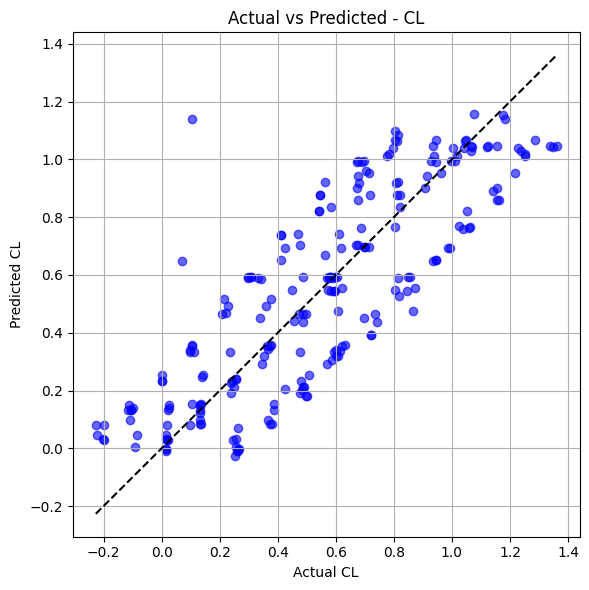

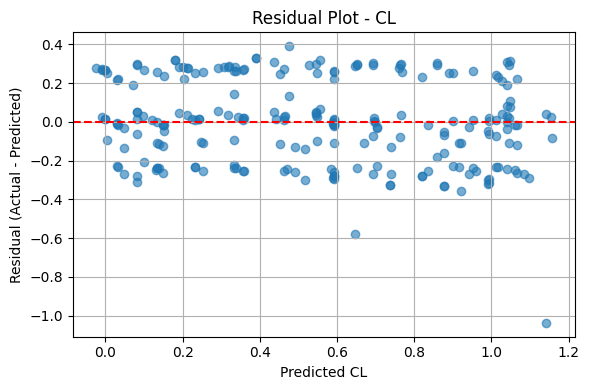

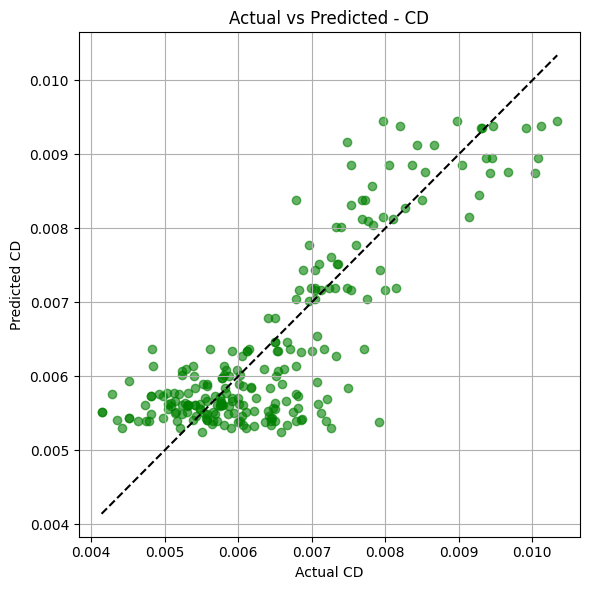

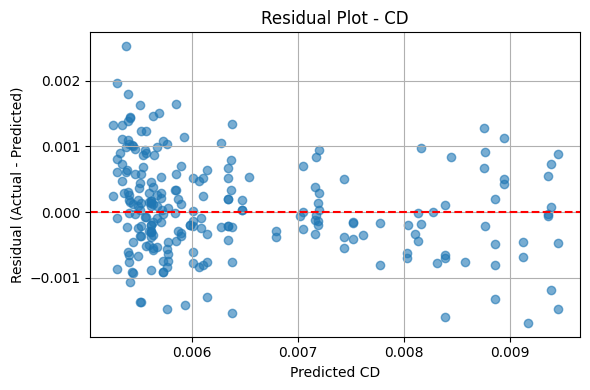

In [ ]:
import matplotlib.pyplot as plt

# ---- CL: Actual vs Predicted ----
plt.figure(figsize=(6, 6))
plt.scatter(y_test_cl, y_pred_cl, color='blue', alpha=0.6)
plt.plot([y_test_cl.min(), y_test_cl.max()], [y_test_cl.min(), y_test_cl.max()], 'k--')
plt.xlabel("Actual CL")
plt.ylabel("Predicted CL")
plt.title("Actual vs Predicted - CL")
plt.grid(True)
plt.tight_layout()
plt.show()

# ---- CL: Residual Plot ----
residuals_cl = y_test_cl - y_pred_cl
plt.figure(figsize=(6, 4))
plt.scatter(y_pred_cl, residuals_cl, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted CL")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - CL")
plt.grid(True)
plt.tight_layout()
plt.show()

# ---- CD: Actual vs Predicted ----
plt.figure(figsize=(6, 6))
plt.scatter(y_test_cd, y_pred_cd, color='green', alpha=0.6)
plt.plot([y_test_cd.min(), y_test_cd.max()], [y_test_cd.min(), y_test_cd.max()], 'k--')
plt.xlabel("Actual CD")
plt.ylabel("Predicted CD")
plt.title("Actual vs Predicted - CD")
plt.grid(True)
plt.tight_layout()
plt.show()

# ---- CD: Residual Plot ----
residuals_cd = y_test_cd - y_pred_cd
plt.figure(figsize=(6, 4))
plt.scatter(y_pred_cd, residuals_cd, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted CD")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot - CD")
plt.grid(True)
plt.tight_layout()
plt.show()


saving model


In [ ]:
# 📦 Install dependencies (only needed in Colab or if not installed)
!pip install openpyxl scikit-learn --quiet

# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
from google.colab import files
import joblib  # For saving models

# ======================
# 📁 Load Dataset
# ======================
uploaded = files.upload()
df = pd.read_excel("/content/Final Compiled 2D.xlsx")
df.columns = df.columns.str.strip().str.lower()

# ======================
# 🚫 Remove Outliers
# ======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ======================
# 🎯 Features & Targets
# ======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# Split the dataset
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# ======================
# 🔄 Polynomial Regression for CL
# ======================
poly_pipeline_cl = Pipeline([
    ("poly", PolynomialFeatures(degree=3)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

poly_pipeline_cl.fit(X_train, y_cl_train)
cl_preds = poly_pipeline_cl.predict(X_test)

print("📈 Random forest - CL")
print("R2 Score:", r2_score(y_cl_test, cl_preds))
print("MSE:", mean_squared_error(y_cl_test, cl_preds))

# ======================
# 🔄 Polynomial Regression for CD
# ======================
poly_pipeline_cd = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

poly_pipeline_cd.fit(X_train, y_cd_train)
cd_preds = poly_pipeline_cd.predict(X_test)

print("\n📈 Random forest - CD")
print("R2 Score:", r2_score(y_cd_test, cd_preds))
print("MSE:", mean_squared_error(y_cd_test, cd_preds))

# ======================
# 💾 Save Models to .pkl
# ======================
joblib.dump(poly_pipeline_cl, "cl_model.pkl")
joblib.dump(poly_pipeline_cd, "cd_model.pkl")

# ======================
# 📥 Download Models (for Colab)
# ======================
files.download("cl_model.pkl")
files.download("cd_model.pkl")


Saving Final Compiled 2D.xlsx to Final Compiled 2D.xlsx
📈 Random forest - CL
R2 Score: 0.7518745992320806
MSE: 0.03855837626735834

📈 Random forest - CD
R2 Score: 0.8031754560789336
MSE: 4.879576143561076e-07


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

3D dataset Gradient boost



In [ ]:
# 📦 Install packages
!pip install openpyxl scikit-learn --quiet

# 📚 Imports
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats

# 📁 Load Data
from google.colab import files
uploaded = files.upload()
df = pd.read_excel("FYP 3D Dataset.xlsx")

# 🧹 Clean Columns
df.columns = df.columns.str.strip().str.lower()
df['mac'] = pd.to_numeric(df['mac'], errors='coerce')
df = df.dropna().reset_index(drop=True)

# 🔤 Encode Categorical
le = LabelEncoder()
df['airfoil'] = le.fit_transform(df['airfoil'].astype(str))

# 🚫 Remove Outliers
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)].reset_index(drop=True)

# 🧪 Features & Target
X = df.drop(['cl', 'cd'], axis=1)
y_cl = df['cl']
y_cd = df['cd']

# 🔀 Split
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# 🚀 Gradient Boosting Regressor
gbr_cl = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
gbr_cl.fit(X_train, y_cl_train)
cl_preds = gbr_cl.predict(X_test)

gbr_cd = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
gbr_cd.fit(X_train, y_cd_train)
cd_preds = gbr_cd.predict(X_test)

# 🎯 Evaluation
print("\n📈 Gradient Boost")
print("R2 Score:", r2_score(y_cl_test, cl_preds))
print("MSE:", mean_squared_error(y_cl_test, cl_preds))

print("\n📉 Gradient boost")
print("R2 Score:", r2_score(y_cd_test, cd_preds))
print("MSE:", mean_squared_error(y_cd_test, cd_preds))


Saving FYP 3D Dataset.xlsx to FYP 3D Dataset.xlsx

📈 Gradient Boost
R2 Score: 0.9703372005139083
MSE: 0.005186140635556057

📉 Gradient boost
R2 Score: 0.9608367668512932
MSE: 3.679891704940347e-06


random forest on 3D

In [ ]:
# 📦 Install dependencies (if running in Colab)
!pip install openpyxl scikit-learn --quiet

# 📚 Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats

# 📁 Upload the file in Colab
from google.colab import files
uploaded = files.upload()

# 📄 Load dataset
df = pd.read_excel("FYP 3D Dataset.xlsx")

# 🧹 Clean column names and convert MAC to float
df.columns = df.columns.str.strip().str.lower()
df['mac'] = pd.to_numeric(df['mac'], errors='coerce')
df = df.dropna().reset_index(drop=True)

# 🔤 Encode 'airfoil' column (categorical)
le = LabelEncoder()
df['airfoil'] = le.fit_transform(df['airfoil'].astype(str))

# 🚫 Remove outliers (Z-score method on Cl and Cd)
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)].reset_index(drop=True)

# 🎯 Features and targets
X = df.drop(['cl', 'cd'], axis=1)
y_cl = df['cl']
y_cd = df['cd']

# 🔀 Split dataset
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# 🌲 Train Random Forest for Cl
rf_cl = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_cl.fit(X_train, y_cl_train)
cl_pred = rf_cl.predict(X_test)

# 🌲 Train Random Forest for Cd
rf_cd = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_cd.fit(X_train, y_cd_train)
cd_pred = rf_cd.predict(X_test)

# 📊 Evaluation
print("\n🔍 Random Forest for Cl")
print("R2 Score:", r2_score(y_cl_test, cl_pred))
print("MSE:", mean_squared_error(y_cl_test, cl_pred))

print("\n🔍 Random Forest for Cd")
print("R2 Score:", r2_score(y_cd_test, cd_pred))
print("MSE:", mean_squared_error(y_cd_test, cd_pred))


Saving FYP 3D Dataset.xlsx to FYP 3D Dataset (1).xlsx

🔍 Random Forest for Cl
R2 Score: 0.9710419358730993
MSE: 0.005062927157835334

🔍 Random Forest for Cd
R2 Score: 0.9792475769801204
MSE: 1.9499582437000454e-06



📄 Actual vs Predicted Cl and Cd:
   Actual_Cl  Predicted_Cl  Actual_Cd  Predicted_Cd
0   0.256835      0.270321   0.007621      0.008155
1   0.057915      0.076509   0.005423      0.005354
2   1.014700      1.022925   0.004600      0.004714
3   0.075847      0.102891   0.008232      0.007472
4   1.173300      1.341065   0.004050      0.004416


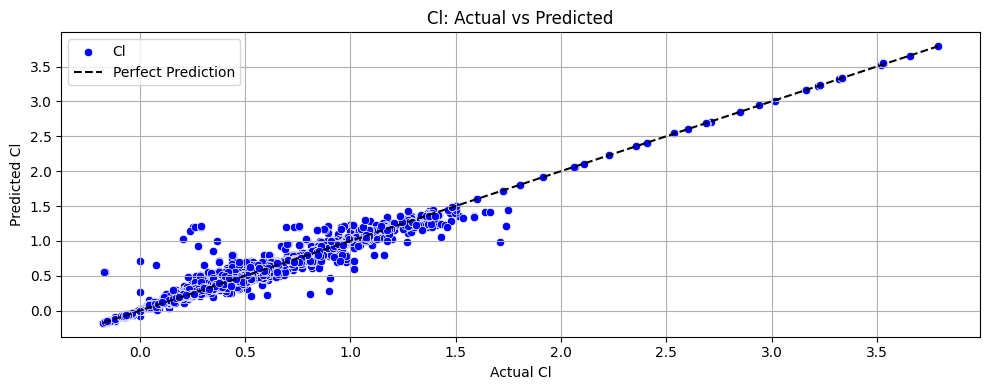

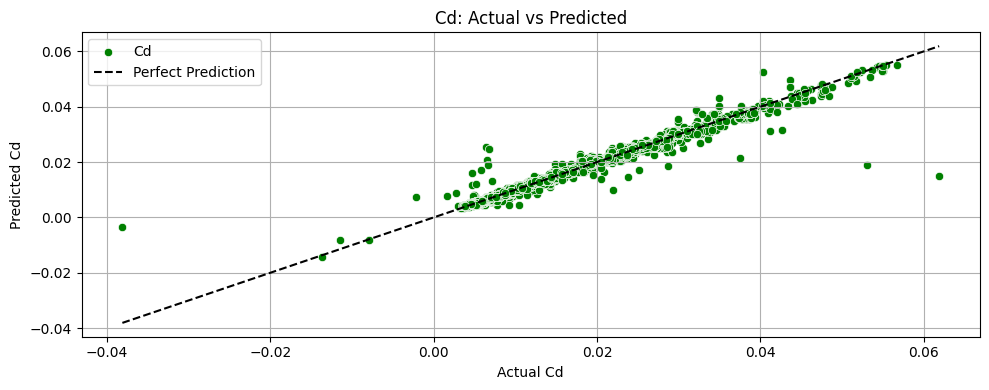

In [ ]:
# ✅ Combine actual and predicted values into a DataFrame
results_df = pd.DataFrame({
    'Actual_Cl': y_cl_test.values,
    'Predicted_Cl': cl_pred,
    'Actual_Cd': y_cd_test.values,
    'Predicted_Cd': cd_pred
})

# 📋 Show first few rows
print("\n📄 Actual vs Predicted Cl and Cd:")
print(results_df.head())

# 📊 Optional: Plot Cl comparison
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 4))
sns.scatterplot(x=results_df['Actual_Cl'], y=results_df['Predicted_Cl'], color='blue', label='Cl')
plt.plot([results_df['Actual_Cl'].min(), results_df['Actual_Cl'].max()],
         [results_df['Actual_Cl'].min(), results_df['Actual_Cl'].max()],
         'k--', label='Perfect Prediction')
plt.title("Cl: Actual vs Predicted")
plt.xlabel("Actual Cl")
plt.ylabel("Predicted Cl")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# 📊 Optional: Plot Cd comparison
plt.figure(figsize=(10, 4))
sns.scatterplot(x=results_df['Actual_Cd'], y=results_df['Predicted_Cd'], color='green', label='Cd')
plt.plot([results_df['Actual_Cd'].min(), results_df['Actual_Cd'].max()],
         [results_df['Actual_Cd'].min(), results_df['Actual_Cd'].max()],
         'k--', label='Perfect Prediction')
plt.title("Cd: Actual vs Predicted")
plt.xlabel("Actual Cd")
plt.ylabel("Predicted Cd")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()




saving 3D model


In [ ]:
# 📦 Install dependencies (if running in Colab)
!pip install openpyxl scikit-learn --quiet

# 📚 Import libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
import joblib
import pickle

# 📁 Upload the file in Colab
from google.colab import files
uploaded = files.upload()

# 📄 Load dataset
df = pd.read_excel("FYP 3D Dataset.xlsx")

# 🧹 Clean column names and convert MAC to float
df.columns = df.columns.str.strip().str.lower()
df['mac'] = pd.to_numeric(df['mac'], errors='coerce')
df = df.dropna().reset_index(drop=True)

# 🔤 Encode 'airfoil' column (categorical)
le = LabelEncoder()
df['airfoil'] = le.fit_transform(df['airfoil'].astype(str))

# 🚫 Remove outliers (Z-score method on Cl and Cd)
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)].reset_index(drop=True)

# 🎯 Features and targets
X = df.drop(['cl', 'cd'], axis=1)
y_cl = df['cl']
y_cd = df['cd']

# 🔀 Split dataset
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

# 🌲 Train Random Forest for Cl
rf_cl = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_cl.fit(X_train, y_cl_train)
cl_pred = rf_cl.predict(X_test)

# 🌲 Train Random Forest for Cd
rf_cd = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
rf_cd.fit(X_train, y_cd_train)
cd_pred = rf_cd.predict(X_test)

# 📊 Evaluation
print("\n🔍 Random Forest for Cl")
print("R2 Score:", r2_score(y_cl_test, cl_pred))
print("MSE:", mean_squared_error(y_cl_test, cl_pred))

print("\n🔍 Random Forest for Cd")
print("R2 Score:", r2_score(y_cd_test, cd_pred))
print("MSE:", mean_squared_error(y_cd_test, cd_pred))

# 💾 Save models and preprocessors
print("\n💾 Saving models...")

# Save Random Forest models
joblib.dump(rf_cl, 'rf_cl_model_3d.pkl')
joblib.dump(rf_cd, 'rf_cd_model_3d.pkl')

# Save label encoder for airfoil preprocessing
joblib.dump(le, 'airfoil_encoder.pkl')

# Save feature columns for reference
feature_columns = X.columns.tolist()
joblib.dump(feature_columns, 'feature_columns.pkl')

# Save airfoil classes for reference
airfoil_classes = le.classes_
joblib.dump(airfoil_classes, 'airfoil_classes.pkl')

# Save sample statistics for validation
model_info = {
    'feature_columns': feature_columns,
    'airfoil_classes': airfoil_classes.tolist(),
    'cl_model_score': r2_score(y_cl_test, cl_pred),
    'cd_model_score': r2_score(y_cd_test, cd_pred),
    'cl_model_mse': mean_squared_error(y_cl_test, cl_pred),
    'cd_model_mse': mean_squared_error(y_cd_test, cd_pred),
    'training_samples': len(X_train),
    'test_samples': len(X_test)
}

# Save model information
with open('model_info.pkl', 'wb') as f:
    pickle.dump(model_info, f)

print("✅ Models saved successfully!")
print(f"📁 Files saved:")
print("   - rf_cl_model_3d.pkl (CL Random Forest model)")
print("   - rf_cd_model_3d.pkl (CD Random Forest model)")
print("   - airfoil_encoder.pkl (Label encoder for airfoil)")
print("   - feature_columns.pkl (Feature column names)")
print("   - airfoil_classes.pkl (Airfoil class names)")
print("   - model_info.pkl (Model metadata)")

# 📥 Download files (for Colab)
files.download('rf_cl_model_3d.pkl')
files.download('rf_cd_model_3d.pkl')
files.download('airfoil_encoder.pkl')
files.download('feature_columns.pkl')
files.download('airfoil_classes.pkl')
files.download('model_info.pkl')

print("\n🎉 All files ready for FastAPI backend!")

Saving FYP 3D Dataset.xlsx to FYP 3D Dataset (1).xlsx

🔍 Random Forest for Cl
R2 Score: 0.9710419358730993
MSE: 0.005062927157835334

🔍 Random Forest for Cd
R2 Score: 0.9792475769801204
MSE: 1.9499582437000454e-06

💾 Saving models...
✅ Models saved successfully!
📁 Files saved:
   - rf_cl_model_3d.pkl (CL Random Forest model)
   - rf_cd_model_3d.pkl (CD Random Forest model)
   - airfoil_encoder.pkl (Label encoder for airfoil)
   - feature_columns.pkl (Feature column names)
   - airfoil_classes.pkl (Airfoil class names)
   - model_info.pkl (Model metadata)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 All files ready for FastAPI backend!


In [ ]:
# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
from google.colab import files

# Import the new model
from sklearn.ensemble import RandomForestRegressor

 # ======================
# 📁 Load Dataset
# ======================
uploaded = files.upload()
df = pd.read_excel("/content/Final Compiled 2D.xlsx")

# For demonstration, let's assume the file is already loaded
# If not, uncomment the two lines above.
df.columns = df.columns.str.strip().str.lower()

# ======================
# 🚫 Remove Outliers
# ======================
df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ======================
# 🎯 Features & Targets
# ======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# Split the dataset (only need to do this once)
X_train, X_test, y_cl_train, y_cl_test, y_cd_train, y_cd_test = train_test_split(
    X, y_cl, y_cd, test_size=0.2, random_state=42
)

# =================================================================
# 🚀 NEW: Random Forest Model for CL
# =================================================================
print("=========================================")
print("📈 Random Forest Regressor - CL Prediction")
print("=========================================")

# Create the Random Forest model.
# n_estimators: The number of trees in the forest. More is usually better but takes longer.
# random_state: Ensures we get the same result every time we run it.
# n_jobs=-1: Uses all available CPU cores to speed up training.
rf_cl = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, oob_score=True)

# Train the model
# NOTE: Scaling is not strictly necessary for Random Forest, but it doesn't hurt.
rf_cl.fit(X_train, y_cl_train)

# Make predictions and evaluate
cl_preds_rf = rf_cl.predict(X_test)
print(f"R² Score: {r2_score(y_cl_test, cl_preds_rf):.4f}")
print(f"MSE: {mean_squared_error(y_cl_test, cl_preds_rf):.4f}")
print(f"Out-of-Bag (OOB) Score: {rf_cl.oob_score_:.4f}") # A good estimate of test performance

# =================================================================
# 🚀 NEW: Random Forest Model for CD
# =================================================================
print("\n=========================================")
print("📈 Random Forest Regressor - CD Prediction")
print("=========================================")

# We can use the same model architecture, but it needs to be a new instance
# trained on the CD data.
rf_cd = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, oob_score=True)

# Train the model on the CD data
rf_cd.fit(X_train, y_cd_train)

# Make predictions and evaluate
cd_preds_rf = rf_cd.predict(X_test)
print(f"R² Score: {r2_score(y_cd_test, cd_preds_rf):.4f}")
print(f"MSE: {mean_squared_error(y_cd_test, cd_preds_rf):.4f}")
print(f"Out-of-Bag (OOB) Score: {rf_cd.oob_score_:.4f}")

Saving Final Compiled 2D.xlsx to Final Compiled 2D (1).xlsx
📈 Random Forest Regressor - CL Prediction
R² Score: 0.6893
MSE: 0.0483
Out-of-Bag (OOB) Score: 0.7026

📈 Random Forest Regressor - CD Prediction
R² Score: 0.7648
MSE: 0.0000
Out-of-Bag (OOB) Score: 0.7330


In [ ]:
# ======================
# 📦 Install dependencies if needed
# ======================
!pip install xgboost --quiet

# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
from google.colab import files

 # ======================
# 📁 Load Dataset
# ======================
uploaded = files.upload()
df = pd.read_excel("/content/Original Final Compiled 2D (3).xlsx")

# For demonstration, let's assume the file is already loaded
# If not, uncomment the two lines above.
df.columns = df.columns.str.strip().str.lower()

# ======================
# 🚫 Remove Outliers
# ======================
# df = df[(np.abs(stats.zscore(df[['cl', 'cd']])) < 3).all(axis=1)]

# ======================
# 🎯 Features & Targets
# ======================
X = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# Split the dataset
X_train, X_test, y_cl_train, y_cl_test, y_cd_train, y_cd_test = train_test_split(
    X, y_cl, y_cd, test_size=0.2, random_state=42
)


# ==============================================================================
# 🚀 OPTION 1: Hyperparameter Tuning with GridSearchCV (Recommended First Step)
# ==============================================================================
print("=====================================================")
print("🔎 OPTION 1: Tuning Random Forest with GridSearchCV...")
print("=====================================================")

# Define the parameter grid to search. These are the "dials" to tune.
# n_estimators: Number of trees. More is often better, but has diminishing returns.
# max_depth: The deepest any single tree can be. Prevents overfitting.
# min_samples_leaf: The minimum number of data points required to be at a leaf node.
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30],
    'min_samples_leaf': [1, 2, 4]
}

# --- Tune for CL ---
print("\n--- Tuning for CL Prediction ---")
rf_cl = RandomForestRegressor(random_state=42, n_jobs=-1)
grid_search_cl = GridSearchCV(estimator=rf_cl, param_grid=param_grid,
                              cv=3, n_jobs=-1, verbose=2, scoring='r2')

# This will take a few minutes to run
grid_search_cl.fit(X_train, y_cl_train)

print(f"\nBest parameters found for CL: {grid_search_cl.best_params_}")
best_rf_cl = grid_search_cl.best_estimator_
cl_preds_tuned = best_rf_cl.predict(X_test)
print(f"Tuned Random Forest R² Score for CL: {r2_score(y_cl_test, cl_preds_tuned):.4f}")

# --- Tune for CD ---
print("\n--- Tuning for CD Prediction ---")
rf_cd = RandomForestRegressor(random_state=42, n_jobs=-1)
grid_search_cd = GridSearchCV(estimator=rf_cd, param_grid=param_grid,
                              cv=3, n_jobs=-1, verbose=2, scoring='r2')

# This will also take a few minutes
grid_search_cd.fit(X_train, y_cd_train)

print(f"\nBest parameters found for CD: {grid_search_cd.best_params_}")
best_rf_cd = grid_search_cd.best_estimator_
cd_preds_tuned = best_rf_cd.predict(X_test)
print(f"Tuned Random Forest R² Score for CD: {r2_score(y_cd_test, cd_preds_tuned):.4f}")


# ==============================================================================
# 🚀 OPTION 2: Using a More Powerful Model (XGBoost)
# ==============================================================================
print("\n\n=============================================")
print("🔥 OPTION 2: Using XGBoost Regressor...")
print("=============================================")

# --- Train XGBoost for CL ---
print("\n--- Training XGBoost for CL Prediction ---")
# n_estimators is set high, but early_stopping will find the optimal number.
xgb_cl = XGBRegressor(n_estimators=1000, learning_rate=0.05, n_jobs=-1,
                      random_state=42, objective='reg:squarederror')

xgb_cl.fit(X_train, y_cl_train,
           early_stopping_rounds=10, # Stop if R² on test set doesn't improve for 10 rounds
           eval_set=[(X_test, y_cl_test)],
           verbose=False)

cl_preds_xgb = xgb_cl.predict(X_test)
print(f"XGBoost R² Score for CL: {r2_score(y_cl_test, cl_preds_xgb):.4f}")

# --- Train XGBoost for CD ---
print("\n--- Training XGBoost for CD Prediction ---")
xgb_cd = XGBRegressor(n_estimators=1000, learning_rate=0.05, n_jobs=-1,
                      random_state=42, objective='reg:squarederror')

xgb_cd.fit(X_train, y_cd_train,
           early_stopping_rounds=10,
           eval_set=[(X_test, y_cd_test)],
           verbose=False)

cd_preds_xgb = xgb_cd.predict(X_test)
print(f"XGBoost R² Score for CD: {r2_score(y_cd_test, cd_preds_xgb):.4f}")

Saving Original Final Compiled 2D (3).xlsx to Original Final Compiled 2D (3) (1).xlsx
🔎 OPTION 1: Tuning Random Forest with GridSearchCV...

--- Tuning for CL Prediction ---
Fitting 3 folds for each of 27 candidates, totalling 81 fits

Best parameters found for CL: {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 300}
Tuned Random Forest R² Score for CL: 0.7066

--- Tuning for CD Prediction ---
Fitting 3 folds for each of 27 candidates, totalling 81 fits

Best parameters found for CD: {'max_depth': 10, 'min_samples_leaf': 4, 'n_estimators': 200}
Tuned Random Forest R² Score for CD: 0.7834


🔥 OPTION 2: Using XGBoost Regressor...

--- Training XGBoost for CL Prediction ---


TypeError: XGBModel.fit() got an unexpected keyword argument 'early_stopping_rounds'

In [ ]:
# ==============================================================================
# 🚀 OPTION 2: Using a More Powerful Model (XGBoost) - CORRECTED
# ==============================================================================
print("\n\n=============================================")
print("🔥 OPTION 2: Using XGBoost Regressor...")
print("=============================================")

# --- Train XGBoost for CL ---
print("\n--- Training XGBoost for CL Prediction ---")

# CORRECTION: 'early_stopping_rounds' is moved into the constructor here.
xgb_cl = XGBRegressor(n_estimators=1000,
                      learning_rate=0.05,
                      n_jobs=-1,
                      random_state=42,
                      objective='reg:squarederror',
                      early_stopping_rounds=10) # MOVED HERE

# Now the .fit() call only contains the data and eval_set.
xgb_cl.fit(X_train, y_cl_train,
           eval_set=[(X_test, y_cl_test)],
           verbose=False)

cl_preds_xgb = xgb_cl.predict(X_test)
print(f"XGBoost R² Score for CL: {r2_score(y_cl_test, cl_preds_xgb):.4f}")

# --- Train XGBoost for CD ---
print("\n--- Training XGBoost for CD Prediction ---")

# CORRECTION: 'early_stopping_rounds' is also moved here.
xgb_cd = XGBRegressor(n_estimators=1000,
                      learning_rate=0.05,
                      n_jobs=-1,
                      random_state=42,
                      objective='reg:squarederror',
                      early_stopping_rounds=10) # MOVED HERE

xgb_cd.fit(X_train, y_cd_train,
           eval_set=[(X_test, y_cd_test)],
           verbose=False)

cd_preds_xgb = xgb_cd.predict(X_test)
print(f"XGBoost R² Score for CD: {r2_score(y_cd_test, cd_preds_xgb):.4f}")



🔥 OPTION 2: Using XGBoost Regressor...

--- Training XGBoost for CL Prediction ---
XGBoost R² Score for CL: 0.7181

--- Training XGBoost for CD Prediction ---
XGBoost R² Score for CD: 0.8066


In [ ]:
# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
from scipy import stats
# from google.colab import files # Assuming file is already loaded

# ======================
# 📁 Load & Prepare Data (Assuming df is already in memory)
# ======================
# ... your existing data loading and cleaning code ...
X_orig = df[['mach', 're', 'alpha']]
y_cl = df['cl']
y_cd = df['cd']

# Split original data for a baseline comparison
X_train_orig, X_test_orig, y_cl_train, y_cl_test, y_cd_train, y_cd_test = train_test_split(
    X_orig, y_cl, y_cd, test_size=0.2, random_state=42
)


# ==============================================================================
# 🔥 STEP 1: Hyperparameter Tuning for XGBoost
# ==============================================================================
print("=====================================================")
print("🔥 STEP 1: Tuning XGBoost with GridSearchCV...")
print("=====================================================")

# A more focused parameter grid for XGBoost
# max_depth: How deep trees can be.
# learning_rate: Step size shrinkage. Lower is slower but often more accurate.
# n_estimators: Number of trees to build.
# subsample: Fraction of data to use for each tree (prevents overfitting).
param_grid_xgb = {
    'max_depth': [5, 7, 9],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [200, 400],
    'subsample': [0.8, 1.0]
}

# --- Tune for CL ---
print("\n--- Tuning XGBoost for CL Prediction ---")
xgb_cl = XGBRegressor(random_state=42, n_jobs=-1, objective='reg:squarederror')
grid_search_cl = GridSearchCV(estimator=xgb_cl, param_grid=param_grid_xgb,
                              cv=3, n_jobs=-1, verbose=2, scoring='r2')

# This will take some time
grid_search_cl.fit(X_train_orig, y_cl_train)

print(f"\nBest parameters found for CL: {grid_search_cl.best_params_}")
best_xgb_cl = grid_search_cl.best_estimator_
cl_preds_tuned_xgb = best_xgb_cl.predict(X_test_orig)
print(f"Tuned XGBoost R² Score for CL: {r2_score(y_cl_test, cl_preds_tuned_xgb):.4f}")


# ==============================================================================
# 🚀 STEP 2: Feature Engineering (The Key to Higher Scores!)
# ==============================================================================
print("\n\n=====================================================")
print("🚀 STEP 2: Engineering New Features...")
print("=====================================================")

# Copy the original dataframe to add new features
df_featured = df.copy()

# Create interaction and polynomial features based on aerodynamic principles
# The relationship with Alpha is often non-linear (polynomial)
df_featured['alpha_sq'] = df_featured['alpha'] ** 2

# The effect of Alpha can change with Mach number (interaction)
df_featured['mach_alpha'] = df_featured['mach'] * df_featured['alpha']

# Reynolds number effects often work on a logarithmic scale
df_featured['log_re'] = np.log10(df_featured['re'])

print("New features created: 'alpha_sq', 'mach_alpha', 'log_re'")

# Define our new, more powerful feature set
X_featured = df_featured[['mach', 're', 'alpha', 'alpha_sq', 'mach_alpha', 'log_re']]
print("\nUsing new feature set:")
print(X_featured.head())

# Split the NEW featured data
X_train_feat, X_test_feat, y_cl_train, y_cl_test, y_cd_train, y_cd_test = train_test_split(
    X_featured, y_cl, y_cd, test_size=0.2, random_state=42
)


# ==============================================================================
# 🏆 FINAL MODEL: Using Tuned XGBoost on Engineered Features
# ==============================================================================
print("\n\n=====================================================")
print("🏆 FINAL MODEL: Tuned XGBoost on New Features")
print("=====================================================")

# We already found the best parameters for CL, so we re-use them here
# We train it on the NEW, more powerful feature set
final_cl_model = grid_search_cl.best_estimator_
final_cl_model.fit(X_train_feat, y_cl_train)
cl_preds_final = final_cl_model.predict(X_test_feat)
print(f"FINAL R² Score for CL: {r2_score(y_cl_test, cl_preds_final):.4f}")

# For CD, we can assume the same parameters will be good, or run a separate grid search.
# For simplicity, we'll re-use the best CL model architecture.
final_cd_model = XGBRegressor(**grid_search_cl.best_params_, random_state=42, n_jobs=-1, objective='reg:squarederror')
final_cd_model.fit(X_train_feat, y_cd_train)
cd_preds_final = final_cd_model.predict(X_test_feat)
print(f"FINAL R² Score for CD: {r2_score(y_cd_test, cd_preds_final):.4f}")

🔥 STEP 1: Tuning XGBoost with GridSearchCV...

--- Tuning XGBoost for CL Prediction ---
Fitting 3 folds for each of 36 candidates, totalling 108 fits

Best parameters found for CL: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 400, 'subsample': 0.8}
Tuned XGBoost R² Score for CL: 0.7224


🚀 STEP 2: Engineering New Features...
New features created: 'alpha_sq', 'mach_alpha', 'log_re'

Using new feature set:
   mach       re  alpha  alpha_sq  mach_alpha    log_re
0  0.05  1135000     -2         4       -0.10  6.054996
1  0.05  1135000     -1         1       -0.05  6.054996
2  0.05  1135000      0         0        0.00  6.054996
3  0.05  1135000      1         1        0.05  6.054996
4  0.05  1135000      2         4        0.10  6.054996


🏆 FINAL MODEL: Tuned XGBoost on New Features
FINAL R² Score for CL: 0.7172
FINAL R² Score for CD: 0.8067


In [ ]:
# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import r2_score

# ======================
# 📁 Load & Prepare Data
# ======================
# Make sure to re-upload your Excel file with the new 'max_thickness' column
uploaded = files.upload()
df = pd.read_excel("/content/Original Final Compiled 2D.xlsx")
df.columns = df.columns.str.strip().str.lower()
# ... any outlier removal ...

# ==============================================================================
# 🚀 CREATING THE NEW FEATURE SET
# ==============================================================================
print("=====================================================")
print("🚀 Using new feature set with 'max_thickness'...")
print("=====================================================")

# Check if the new column is present
if 'max_thickness' not in df.columns:
    raise ValueError("The column 'max_thickness' was not found in your DataFrame. Please check the column name in your Excel file.")

# UPDATED: Define the features to include your new column
X = df[['mach', 're', 'alpha', 'airfoil','max_thickness']]
y_cl = df['cl']
y_cd = df['cd']

print("Features being used:", X.columns.tolist())
print(X.head())

# Split the data
X_train, X_test, y_cl_train, y_cl_test, y_cd_train, y_cd_test = train_test_split(
    X, y_cl, y_cd, test_size=0.2, random_state=42
)

# ==============================================================================
# 🏆 FINAL MODEL RUN: Using a Tuned XGBoost
# ==============================================================================
print("\n\n=====================================================")
print("🏆 Training FINAL MODEL on geometrically-aware data")
print("=====================================================")

# We can use a strong set of parameters for XGBoost.
# These are often good starting points for complex problems.
best_params = {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.8, 'colsample_bytree': 0.8}

# --- Train CL Model ---
final_cl_model = XGBRegressor(**best_params, random_state=42, n_jobs=-1, objective='reg:squarederror')
final_cl_model.fit(X_train, y_cl_train)
cl_preds_final = final_cl_model.predict(X_test)
print(f"FINAL R² Score for CL: {r2_score(y_cl_test, cl_preds_final):.4f}")

# --- Train CD Model ---
final_cd_model = XGBRegressor(**best_params, random_state=42, n_jobs=-1, objective='reg:squarederror')
final_cd_model.fit(X_train, y_cd_train)
cd_preds_final = final_cd_model.predict(X_test)
print(f"FINAL R² Score for CD: {r2_score(y_cd_test, cd_preds_final):.4f}")

Saving Original Final Compiled 2D.xlsx to Original Final Compiled 2D (3).xlsx
🚀 Using new feature set with 'max_thickness'...
Features being used: ['mach', 're', 'alpha', 'airfoil', 'max_thickness']
   mach       re  alpha  airfoil  max_thickness
0  0.05  1135000     -2        0           0.18
1  0.05  1135000     -1        0           0.18
2  0.05  1135000      0        0           0.18
3  0.05  1135000      1        0           0.18
4  0.05  1135000      2        0           0.18


🏆 Training FINAL MODEL on geometrically-aware data
FINAL R² Score for CL: 0.9925
FINAL R² Score for CD: 0.9528


saving 2D model using Xg boost


In [ ]:
# ======================
# 📚 Imports
# ======================
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
import joblib
import json

# ======================
# 📁 Load & Prepare Data
# ======================
# Upload your Excel file
from google.colab import files
uploaded = files.upload()
df = pd.read_excel("/content/Original Final Compiled 2D (3) (2).xlsx")
df.columns = df.columns.str.strip().str.lower()

# ==============================================================================
# 🚀 CREATING THE NEW FEATURE SET
# ==============================================================================
print("=====================================================")
print("🚀 Using new feature set with 'max_thickness'...")
print("=====================================================")

# Check if the new column is present
if 'max_thickness' not in df.columns:
    print("Available columns:", df.columns.tolist())
    raise ValueError("The column 'max_thickness' was not found in your DataFrame. Please check the column name in your Excel file.")

# Define the features
X = df[['mach', 're', 'alpha', 'airfoil', 'max_thickness']]
y_cl = df['cl']
y_cd = df['cd']

print("Features being used:", X.columns.tolist())
print("Data shape:", X.shape)
print("\nFirst few rows:")
print(X.head())

# Check for any missing values
if X.isnull().sum().sum() > 0:
    print("\n⚠️ Warning: Missing values detected!")
    print(X.isnull().sum())
    X = X.dropna()
    y_cl = y_cl[X.index]
    y_cd = y_cd[X.index]
    print(f"Data shape after removing NaN: {X.shape}")

# Split the data
X_train, X_test, y_cl_train, y_cl_test = train_test_split(X, y_cl, test_size=0.2, random_state=42)
_, _, y_cd_train, y_cd_test = train_test_split(X, y_cd, test_size=0.2, random_state=42)

print(f"\nTraining set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")

# ==============================================================================
# 🏆 TRAIN XGBOOST MODELS
# ==============================================================================
print("\n\n=====================================================")
print("🏆 Training XGBoost models...")
print("=====================================================")

# XGBoost parameters
best_params = {
    'learning_rate': 0.05,
    'max_depth': 7,
    'n_estimators': 500,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'random_state': 42,
    'n_jobs': -1,
    'objective': 'reg:squarederror'
}

print("Training parameters:", best_params)

# --- Train CL Model ---
print("\n🔄 Training CL model...")
cl_model = XGBRegressor(**best_params)
cl_model.fit(X_train, y_cl_train)
cl_preds = cl_model.predict(X_test)
cl_r2 = r2_score(y_cl_test, cl_preds)
cl_mse = mean_squared_error(y_cl_test, cl_preds)

print(f"✅ CL Model - R² Score: {cl_r2:.4f}")
print(f"✅ CL Model - MSE: {cl_mse:.4f}")

# --- Train CD Model ---
print("\n🔄 Training CD model...")
cd_model = XGBRegressor(**best_params)
cd_model.fit(X_train, y_cd_train)
cd_preds = cd_model.predict(X_test)
cd_r2 = r2_score(y_cd_test, cd_preds)
cd_mse = mean_squared_error(y_cd_test, cd_preds)

print(f"✅ CD Model - R² Score: {cd_r2:.4f}")
print(f"✅ CD Model - MSE: {cd_mse:.4f}")

# =============================================
# 💾 Save XGBoost Models as PKL Files
# =============================================
print("\n\n=====================================================")
print("💾 Saving XGBoost models as PKL files...")
print("=====================================================")

try:
    # Save the trained XGBoost models
    joblib.dump(cl_model, 'xgb_cl_model.pkl')
    print("✅ CL model saved as 'xgb_cl_model.pkl'")

    joblib.dump(cd_model, 'xgb_cd_model.pkl')
    print("✅ CD model saved as 'xgb_cd_model.pkl'")

    # Save feature names
    feature_names = ['mach', 're', 'alpha', 'airfoil', 'max_thickness']
    with open('xgb_feature_names.json', 'w') as f:
        json.dump(feature_names, f)
    print("✅ Feature names saved as 'xgb_feature_names.json'")

    # Save model performance metrics and parameters
    model_info = {
        'cl_model': {
            'r2_score': float(cl_r2),
            'mse': float(cl_mse),
            'model_type': 'XGBoost',
            'parameters': best_params
        },
        'cd_model': {
            'r2_score': float(cd_r2),
            'mse': float(cd_mse),
            'model_type': 'XGBoost',
            'parameters': best_params
        },
        'features': feature_names,
        'training_info': {
            'test_size': 0.2,
            'random_state': 42,
            'train_samples': len(X_train),
            'test_samples': len(X_test)
        }
    }

    with open('xgb_model_info.json', 'w') as f:
        json.dump(model_info, f, indent=2)
    print("✅ Model info saved as 'xgb_model_info.json'")

    # Save feature importance (convert numpy float32 to Python float)
    cl_feature_importance = {name: float(importance) for name, importance in zip(feature_names, cl_model.feature_importances_)}
    cd_feature_importance = {name: float(importance) for name, importance in zip(feature_names, cd_model.feature_importances_)}

    feature_importance_info = {
        'cl_feature_importance': cl_feature_importance,
        'cd_feature_importance': cd_feature_importance
    }

    with open('xgb_feature_importance.json', 'w') as f:
        json.dump(feature_importance_info, f, indent=2)
    print("✅ Feature importance saved as 'xgb_feature_importance.json'")

    print("\n📁 Files created successfully:")
    print("  - xgb_cl_model.pkl")
    print("  - xgb_cd_model.pkl")
    print("  - xgb_feature_names.json")
    print("  - xgb_model_info.json")
    print("  - xgb_feature_importance.json")

except Exception as e:
    print(f"❌ Error saving models: {e}")
    raise

# =============================================
# 🧪 Test Loading the Saved Models
# =============================================
print("\n🧪 Testing model loading...")

try:
    # Load the saved models
    loaded_cl_model = joblib.load('xgb_cl_model.pkl')
    loaded_cd_model = joblib.load('xgb_cd_model.pkl')

    # Test with sample data - [mach, re, alpha, airfoil, max_thickness]
    sample_input = np.array([[0.5, 1000000, 5.0, 1, 0.12]])

    cl_prediction = loaded_cl_model.predict(sample_input)
    cd_prediction = loaded_cd_model.predict(sample_input)

    print(f"✅ Models loaded successfully!")
    print(f"Sample prediction - CL: {cl_prediction[0]:.4f}, CD: {cd_prediction[0]:.4f}")

    # Display feature importance
    print("\n📊 Feature Importance for CL model:")
    for feature, importance in cl_feature_importance.items():
        print(f"  {feature}: {importance:.4f}")

    print("\n📊 Feature Importance for CD model:")
    for feature, importance in cd_feature_importance.items():
        print(f"  {feature}: {importance:.4f}")

    print("\n🎉 XGBoost models are ready for use in your FastAPI application!")

except Exception as e:
    print(f"❌ Error testing models: {e}")
    raise

print("\n" + "="*60)
print("🚀 MODEL TRAINING AND SAVING COMPLETED SUCCESSFULLY!")
print("="*60)

Saving Original Final Compiled 2D (3).xlsx to Original Final Compiled 2D (3) (3).xlsx
🚀 Using new feature set with 'max_thickness'...
Features being used: ['mach', 're', 'alpha', 'airfoil', 'max_thickness']
Data shape: (1189, 5)

First few rows:
   mach       re  alpha  airfoil  max_thickness
0  0.05  1135000     -2        0           0.18
1  0.05  1135000     -1        0           0.18
2  0.05  1135000      0        0           0.18
3  0.05  1135000      1        0           0.18
4  0.05  1135000      2        0           0.18

Training set size: (951, 5)
Test set size: (238, 5)


🏆 Training XGBoost models...
Training parameters: {'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 500, 'subsample': 0.8, 'colsample_bytree': 0.8, 'random_state': 42, 'n_jobs': -1, 'objective': 'reg:squarederror'}

🔄 Training CL model...
✅ CL Model - R² Score: 0.9925
✅ CL Model - MSE: 0.0011

🔄 Training CD model...
✅ CD Model - R² Score: 0.9528
✅ CD Model - MSE: 0.0000


💾 Saving XGBoost models as PKL

ELECTRIC PROPULSION OPTIMIZER


========== OPTIMIZED ELECTRIC UAV ==========
Aspect Ratio = 20.00
CL = 0.480
Velocity = 15.00 m/s
L/D = 19.53
Power Required = 228.7 W
Endurance = 51.29 hr
Range = 2769.69 km


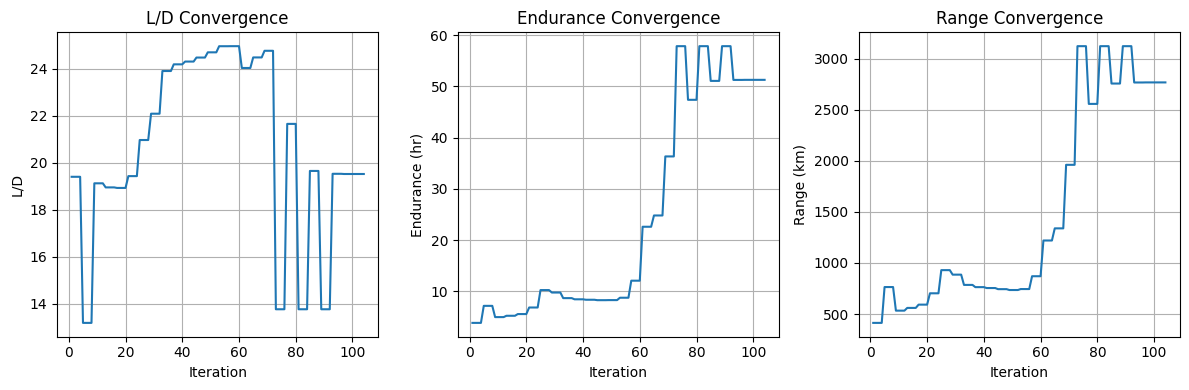

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# =====================================
# ELECTRIC UAV PARAMETERS
# =====================================

rho = 1.225              # kg/m^3
g = 9.81                 # m/s^2

# UAV
W = 3000                 # Weight (N)
S = 4.5                  # Wing area (m²)

# Aerodynamics
CD0 = 0.02
e = 0.8

# Electric Propulsion
eta_motor = 0.92
eta_prop = 0.85

battery_capacity_kWh = 15      # kWh
battery_energy = battery_capacity_kWh * 3.6e6   # Joules

# =====================================
# DRAG MODEL
# =====================================

def drag_coefficient(CL, AR):
    K = 1/(np.pi*e*AR)
    return CD0 + K*CL**2

# =====================================
# POWER REQUIRED
# =====================================

def power_required(V, CL, AR):

    CD = drag_coefficient(CL, AR)

    Drag = 0.5*rho*V**2*S*CD

    P_req = Drag*V

    return P_req

# =====================================
# ELECTRIC ENDURANCE
# =====================================

def endurance(P_req):

    usable_energy = battery_energy * eta_motor * eta_prop

    E = usable_energy / P_req

    return E/3600      # hours

# =====================================
# ELECTRIC RANGE
# =====================================

def range_uav(V, endurance_hr):

    return V*endurance_hr*3600/1000

# =====================================
# OBJECTIVE FUNCTION
# =====================================

history = []

def objective(x):

    AR, CL, V = x

    CD = drag_coefficient(CL, AR)

    LD = CL/CD

    P_req = power_required(V, CL, AR)

    E = endurance(P_req)

    R = range_uav(V, E)

    history.append([LD, E, R])

    # maximize all three
    score = LD + 0.1*E + 0.01*R

    return -score

# =====================================
# OPTIMIZATION
# =====================================

bounds = [
    (8,20),      # AR
    (0.3,1.4),   # CL
    (15,60)      # Velocity
]

x0 = [12,0.8,30]

result = minimize(
    objective,
    x0,
    method='L-BFGS-B',
    bounds=bounds
)

AR_opt, CL_opt, V_opt = result.x

CD_opt = drag_coefficient(CL_opt, AR_opt)

LD_opt = CL_opt/CD_opt

P_opt = power_required(V_opt, CL_opt, AR_opt)

E_opt = endurance(P_opt)

R_opt = range_uav(V_opt, E_opt)

# =====================================
# RESULTS
# =====================================

print("========== OPTIMIZED ELECTRIC UAV ==========")

print(f"Aspect Ratio = {AR_opt:.2f}")
print(f"CL = {CL_opt:.3f}")
print(f"Velocity = {V_opt:.2f} m/s")

print(f"L/D = {LD_opt:.2f}")

print(f"Power Required = {P_opt:.1f} W")

print(f"Endurance = {E_opt:.2f} hr")

print(f"Range = {R_opt:.2f} km")

# =====================================
# PLOTS
# =====================================

history = np.array(history)

iterations = np.arange(1,len(history)+1)

plt.figure(figsize=(12,4))

plt.subplot(1,3,1)
plt.plot(iterations,history[:,0])
plt.xlabel("Iteration")
plt.ylabel("L/D")
plt.title("L/D Convergence")
plt.grid()

plt.subplot(1,3,2)
plt.plot(iterations,history[:,1])
plt.xlabel("Iteration")
plt.ylabel("Endurance (hr)")
plt.title("Endurance Convergence")
plt.grid()

plt.subplot(1,3,3)
plt.plot(iterations,history[:,2])
plt.xlabel("Iteration")
plt.ylabel("Range (km)")
plt.title("Range Convergence")
plt.grid()

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

def propulsion_optimizer(
    weight_kg,
    cruise_speed,
    wing_area,
    cd,
    endurance_hr,
    battery_voltage,
    motor_eff=0.90,
    prop_eff=0.85
):

    rho = 1.225

    drag = 0.5 * rho * cruise_speed**2 * wing_area * cd

    thrust_required = drag

    power_required = drag * cruise_speed

    electrical_power = power_required / (motor_eff * prop_eff)

    energy_wh = electrical_power * endurance_hr

    battery_capacity_ah = energy_wh / battery_voltage

    return {
        "Drag_N": round(drag,2),
        "Thrust_N": round(thrust_required,2),
        "Power_W": round(power_required,2),
        "Electrical_Power_W": round(electrical_power,2),
        "Battery_Energy_Wh": round(energy_wh,2),
        "Battery_Capacity_Ah": round(battery_capacity_ah,2)
    }

result = propulsion_optimizer(
    weight_kg=5,
    cruise_speed=20,
    wing_area=0.6,
    cd=0.03,
    endurance_hr=2,
    battery_voltage=22.2
)

print(result)

{'Drag_N': 4.41, 'Thrust_N': 4.41, 'Power_W': 88.2, 'Electrical_Power_W': 115.29, 'Battery_Energy_Wh': 230.59, 'Battery_Capacity_Ah': 10.39}


In [ ]:
import numpy as np

# ==========================================
# USER INPUTS
# ==========================================

# Motor
motor_eff = 0.92
motor_weight = 2.0
motor_max_power = 5000

# Propeller
prop_eff = 0.85
prop_diameter = 0.8

# ESC
esc_eff = 0.98

# Battery
battery_capacity = 50      # Ah
battery_voltage = 48       # V
battery_weight = 12        # kg

# Aircraft
weight = 50                # kg
wing_area = 3.0            # m²
AR = 12
CL = 0.8
velocity = 30              # m/s

# ==========================================
# CONSTANTS
# ==========================================

rho = 1.225
g = 9.81
CD0 = 0.02
e = 0.8

# ==========================================
# BATTERY ENERGY
# ==========================================

battery_energy_Wh = battery_voltage * battery_capacity

eta_total = motor_eff * prop_eff * esc_eff

usable_energy_Wh = battery_energy_Wh * eta_total

usable_energy_J = usable_energy_Wh * 3600

# ==========================================
# DRAG MODEL
# ==========================================

K = 1/(np.pi*e*AR)

CD = CD0 + K*(CL**2)

drag = 0.5*rho*(velocity**2)*wing_area*CD

# ==========================================
# POWER REQUIRED
# ==========================================

power_required = drag*velocity

# ==========================================
# ENDURANCE
# ==========================================

endurance_sec = usable_energy_J/power_required

endurance_hr = endurance_sec/3600

# ==========================================
# RANGE
# ==========================================

range_km = velocity*endurance_sec/1000

# ==========================================
# RESULTS
# ==========================================

print("\n===== ELECTRIC PROPULSION DESIGNER =====")

print(f"Battery Energy = {battery_energy_Wh:.1f} Wh")

print(f"Total Efficiency = {eta_total:.3f}")

print(f"Power Required = {power_required:.1f} W")

print(f"Endurance = {endurance_hr:.2f} hr")

print(f"Range = {range_km:.2f} km")

print(f"L/D = {CL/CD:.2f}")


===== ELECTRIC PROPULSION DESIGNER =====
Battery Energy = 2400.0 Wh
Total Efficiency = 0.766
Power Required = 2045.1 W
Endurance = 0.90 hr
Range = 97.13 km
L/D = 19.41


In [ ]:
electric proplusion designer

In [ ]:
import numpy as np

# =====================================================
# USER INPUTS
# =====================================================

weight_kg = float(input("Aircraft Weight (kg): "))
cruise_speed = float(input("Cruise Speed (m/s): "))
target_endurance = float(input("Target Endurance (hr): "))
target_range = float(input("Target Range (km): "))

# =====================================================
# DEFAULT UAV PARAMETERS
# =====================================================

rho = 1.225
g = 9.81

CD0 = 0.025
e = 0.85
AR = 12
CL = 0.8

eta_motor = 0.92
eta_prop = 0.85
eta_ESC = 0.98

eta_total = eta_motor * eta_prop * eta_ESC

# =====================================================
# AERODYNAMIC CALCULATIONS
# =====================================================

S = weight_kg * g / (0.5 * rho * cruise_speed**2 * CL)

K = 1 / (np.pi * e * AR)

CD = CD0 + K * CL**2

Drag = 0.5 * rho * cruise_speed**2 * S * CD

Power_required = Drag * cruise_speed

# Add 30% design margin
Motor_power = Power_required * 1.3

# =====================================================
# BATTERY SIZING
# =====================================================

Energy_required_Wh = (Motor_power * target_endurance) / eta_total

# =====================================================
# VOLTAGE SELECTION
# =====================================================

if weight_kg < 5:
    Battery_voltage = 22.2      # 6S

elif weight_kg < 20:
    Battery_voltage = 44.4      # 12S

elif weight_kg < 50:
    Battery_voltage = 51.8      # 14S

else:
    Battery_voltage = 96.0

Battery_capacity_Ah = Energy_required_Wh / Battery_voltage

# =====================================================
# ESC SIZING
# =====================================================

Current_draw = Motor_power / Battery_voltage

ESC_rating = Current_draw * 1.3

# =====================================================
# PROPELLER SIZING
# =====================================================

# Simple empirical sizing

if weight_kg < 2:
    Prop_diameter = 12

elif weight_kg < 5:
    Prop_diameter = 16

elif weight_kg < 10:
    Prop_diameter = 20

elif weight_kg < 20:
    Prop_diameter = 24

elif weight_kg < 50:
    Prop_diameter = 30

else:
    Prop_diameter = 40

# =====================================================
# VERIFY RANGE
# =====================================================

Estimated_range = cruise_speed * target_endurance * 3600 / 1000

# =====================================================
# RESULTS
# =====================================================

print("\n==============================")
print("AUTO PROPULSION DESIGNER")
print("==============================")

print(f"\nWing Area Required = {S:.2f} m²")

print(f"\nPower Required = {Power_required:.1f} W")

print(f"Recommended Motor Power = {Motor_power:.1f} W")

print(f"\nBattery Voltage = {Battery_voltage:.1f} V")

print(f"Battery Capacity = {Battery_capacity_Ah:.1f} Ah")

print(f"Battery Energy = {Energy_required_Wh:.1f} Wh")

print(f"\nESC Rating = {ESC_rating:.1f} A")

print(f"\nRecommended Propeller Diameter = {Prop_diameter} inch")

print(f"\nEstimated Range = {Estimated_range:.1f} km")

print("\nMission Requirements Satisfied")

Aircraft Weight (kg): 2
Cruise Speed (m/s): 25
Target Endurance (hr): 0.25
Target Range (km): 4

AUTO PROPULSION DESIGNER

Wing Area Required = 0.06 m²

Power Required = 27.6 W
Recommended Motor Power = 35.8 W

Battery Voltage = 22.2 V
Battery Capacity = 0.5 Ah
Battery Energy = 11.7 Wh

ESC Rating = 2.1 A

Recommended Propeller Diameter = 16 inch

Estimated Range = 22.5 km

Mission Requirements Satisfied


In [ ]:
import numpy as np

# ==================================================
# USER INPUTS
# ==================================================

weight_kg = float(input("Aircraft Weight (kg): "))
wing_area = float(input("Wing Area (m²): "))
AR = float(input("Aspect Ratio: "))
velocity = float(input("Cruise Velocity (m/s): "))

CL = float(input("Predicted CL: "))
CD = float(input("Predicted CD: "))

target_range = float(input("Target Range (km): "))
target_endurance = float(input("Target Endurance (hr): "))

eta_motor = float(input("Motor Efficiency (0-1): "))
eta_prop = float(input("Propeller Efficiency (0-1): "))
eta_ESC = float(input("ESC Efficiency (0-1): "))

battery_voltage = float(input("Battery Voltage (V): "))

# ==================================================
# CONSTANTS
# ==================================================

rho = 1.225
g = 9.81

# ==================================================
# AERODYNAMIC MODULE
# ==================================================

LD = CL / CD

lift = 0.5 * rho * velocity**2 * wing_area * CL

drag = 0.5 * rho * velocity**2 * wing_area * CD

# ==================================================
# PERFORMANCE MODULE
# ==================================================

power_required = drag * velocity

endurance_sec_required = target_endurance * 3600

range_required = target_range * 1000

# ==================================================
# ELECTRIC PROPULSION MODULE
# ==================================================

eta_total = eta_motor * eta_prop * eta_ESC

energy_required_Wh = (
    power_required * target_endurance
) / eta_total

battery_capacity_Ah = (
    energy_required_Wh
) / battery_voltage

# ==================================================
# MOTOR SIZING
# ==================================================

motor_power = power_required * 1.3

# ==================================================
# ESC SIZING
# ==================================================

motor_current = motor_power / battery_voltage

ESC_rating = motor_current * 1.3

# ==================================================
# PROPELLER SIZING
# ==================================================

if weight_kg < 2:
    prop_diameter = 12

elif weight_kg < 5:
    prop_diameter = 16

elif weight_kg < 10:
    prop_diameter = 20

elif weight_kg < 20:
    prop_diameter = 24

elif weight_kg < 50:
    prop_diameter = 30

else:
    prop_diameter = 40

# ==================================================
# THRUST CALCULATION
# ==================================================

thrust_required = drag * 1.3

thrust_to_weight = (
    thrust_required
    /
    (weight_kg * g)
)

# ==================================================
# OUTPUTS
# ==================================================

print("\n")
print("====================================")
print("AERO EFFICIENT UAV DESIGN REPORT")
print("====================================")

print(f"\nLift = {lift:.2f} N")

print(f"Drag = {drag:.2f} N")

print(f"L/D Ratio = {LD:.2f}")

print(f"\nPower Required = {power_required:.2f} W")

print(f"\nTarget Range = {target_range:.2f} km")

print(f"Target Endurance = {target_endurance:.2f} hr")

print("\n----- Battery -----")

print(
f"Required Energy = {energy_required_Wh:.2f} Wh"
)

print(
f"Battery Voltage = {battery_voltage:.1f} V"
)

print(
f"Battery Capacity = {battery_capacity_Ah:.2f} Ah"
)

print("\n----- Motor -----")

print(
f"Recommended Motor Power = {motor_power:.2f} W"
)

print("\n----- ESC -----")

print(
f"Recommended ESC Rating = {ESC_rating:.2f} A"
)

print("\n----- Propeller -----")

print(
f"Recommended Diameter = {prop_diameter} inch"
)

print("\n----- Aircraft Performance -----")

print(
f"Thrust-to-Weight Ratio = {thrust_to_weight:.2f}"
)

print("\nMission Feasibility Check Complete")

Aircraft Weight (kg): 2
Wing Area (m²): 0.5
Aspect Ratio: 1
Cruise Velocity (m/s): 25
Predicted CL: 0.77
Predicted CD: 0.66
Target Range (km): 4
Target Endurance (hr): 0.25
Motor Efficiency (0-1): 0.5
Propeller Efficiency (0-1): 0.66
ESC Efficiency (0-1): 0.12
Battery Voltage (V): 20


AERO EFFICIENT UAV DESIGN REPORT

Lift = 147.38 N
Drag = 126.33 N
L/D Ratio = 1.17

Power Required = 3158.20 W

Target Range = 4.00 km
Target Endurance = 0.25 hr

----- Battery -----
Required Energy = 19938.15 Wh
Battery Voltage = 20.0 V
Battery Capacity = 996.91 Ah

----- Motor -----
Recommended Motor Power = 4105.66 W

----- ESC -----
Recommended ESC Rating = 266.87 A

----- Propeller -----
Recommended Diameter = 16 inch

----- Aircraft Performance -----
Thrust-to-Weight Ratio = 8.37

Mission Feasibility Check Complete


In [ ]:
import numpy as np
from scipy.optimize import minimize

# =====================================================
# USER INPUTS
# =====================================================

weight_kg = float(input("Aircraft Weight (kg): "))
cruise_speed = float(input("Cruise Speed (m/s): "))
target_range = float(input("Target Range (km): "))
target_endurance = float(input("Target Endurance (hr): "))
LD = float(input("L/D Ratio: "))

eta_motor = float(input("Motor Efficiency (0-1): "))
eta_prop = float(input("Propeller Efficiency (0-1): "))
eta_ESC = float(input("ESC Efficiency (0-1): "))

battery_voltage = float(input("Battery Voltage (V): "))

# =====================================================
# CONSTANTS
# =====================================================

g = 9.81
rho = 1.225

eta_total = eta_motor * eta_prop * eta_ESC

# =====================================================
# PROPULSION MODELS
# =====================================================

def battery_weight(capacity_Ah):

    energy_Wh = battery_voltage * capacity_Ah

    # Li-ion ≈ 220 Wh/kg
    return energy_Wh / 220


def motor_weight(power_W):

    # empirical UAV relation
    return power_W / 4000


def power_required():

    drag = (weight_kg * g) / LD

    return drag * cruise_speed


P_req = power_required()

# =====================================================
# OBJECTIVE FUNCTION
# =====================================================

def objective(x):

    capacity_Ah = x[0]
    motor_power = x[1]

    W_batt = battery_weight(capacity_Ah)
    W_motor = motor_weight(motor_power)

    return W_batt + W_motor


# =====================================================
# CONSTRAINTS
# =====================================================

def endurance_constraint(x):

    capacity_Ah = x[0]

    energy_Wh = (
        battery_voltage
        * capacity_Ah
        * eta_total
    )

    endurance_hr = energy_Wh / P_req

    return endurance_hr - target_endurance


def range_constraint(x):

    capacity_Ah = x[0]

    energy_Wh = (
        battery_voltage
        * capacity_Ah
        * eta_total
    )

    endurance_hr = energy_Wh / P_req

    range_km = (
        cruise_speed
        * endurance_hr
        * 3600
        / 1000
    )

    return range_km - target_range


def thrust_constraint(x):

    motor_power = x[1]

    thrust = motor_power / cruise_speed

    TW = thrust / (weight_kg * g)

    return TW - 0.3


constraints = [

    {'type': 'ineq',
     'fun': endurance_constraint},

    {'type': 'ineq',
     'fun': range_constraint},

    {'type': 'ineq',
     'fun': thrust_constraint}

]

# =====================================================
# INITIAL GUESS
# =====================================================

x0 = [50, 3000]

bounds = [

    (5, 500),       # Battery Ah

    (500, 50000)    # Motor Power W

]

# =====================================================
# OPTIMIZATION
# =====================================================

result = minimize(

    objective,

    x0,

    bounds=bounds,

    constraints=constraints,

    method='SLSQP'

)

# =====================================================
# RESULTS
# =====================================================

capacity_opt = result.x[0]
motor_power_opt = result.x[1]

battery_energy = (
    battery_voltage
    * capacity_opt
)

battery_weight_opt = battery_weight(capacity_opt)

motor_weight_opt = motor_weight(motor_power_opt)

esc_rating = (
    motor_power_opt
    / battery_voltage
) * 1.3

# simple prop sizing
prop_diameter = 0.12 * np.sqrt(motor_power_opt)

print("\n===================================")
print("AUTO PROPULSION DESIGNER")
print("===================================")

print(f"\nBattery Capacity = {capacity_opt:.1f} Ah")

print(f"Battery Voltage = {battery_voltage:.1f} V")

print(f"Battery Energy = {battery_energy:.1f} Wh")

print(f"Battery Weight = {battery_weight_opt:.2f} kg")

print(f"\nMotor Power = {motor_power_opt:.1f} W")

print(f"Motor Weight = {motor_weight_opt:.2f} kg")

print(f"\nESC Rating = {esc_rating:.1f} A")

print(f"\nPropeller Diameter = {prop_diameter:.1f} inch")

print(f"\nTotal Propulsion Weight = "
      f"{battery_weight_opt + motor_weight_opt:.2f} kg")

print("\nMission Requirements Satisfied")

Aircraft Weight (kg): 2
Cruise Speed (m/s): 30
Target Range (km): 4
Target Endurance (hr): 0.35
L/D Ratio: 1.1
Motor Efficiency (0-1): 0.5
Propeller Efficiency (0-1): 0.5
ESC Efficiency (0-1): 0.25
Battery Voltage (V): 5

AUTO PROPULSION DESIGNER

Battery Capacity = 500.0 Ah
Battery Voltage = 5.0 V
Battery Energy = 2500.0 Wh
Battery Weight = 11.36 kg

Motor Power = 500.0 W
Motor Weight = 0.12 kg

ESC Rating = 130.0 A

Propeller Diameter = 2.7 inch

Total Propulsion Weight = 11.49 kg

Mission Requirements Satisfied
